# USED SMARTPHONE PRICE PREDICTION

#### ZEESHAN AHMAD ABBASI
#### FA24-BSE-181 | MACHINE LEARNING
#### Assignment 03


## 🌐 Live Deployment URL: ⏳ (https://used-smartphone-price.streamlit.app/)


# Used Smartphone Price Prediction – 10-Fold Cross Validation (Full Dataset)

**COMSATS University Islamabad, Lahore Campus** · Machine Learning Fundamentals (AIC354) · Assignment 3
*Applying, Evaluating, and Comparing Multiple ML Algorithms on Large Real-World Dataset*

| | |
|---|---|
| **Problem** | Predict the resale price of a used / refurbished phone or tablet (regression) |
| **Dataset** | [Used Phones & Tablets Pricing Dataset (Kaggle, ahsan81)](https://www.kaggle.com/datasets/ahsan81/used-handheld-device-data) – **3,454 devices, 15 columns**, CC0 Public Domain |
| **Algorithms (5)** | SVR · Extra Trees · AdaBoost · Histogram Gradient Boosting · MLP Neural Network |
| **Evaluation** | 10-fold cross validation on the **full** dataset · RMSE (primary), MAE, R² |
| **Deployed model** | `smartphone_price_model.joblib` (complete scikit-learn pipeline) |
| **Web app** | *Smartphone Resale Price Predictor* (Streamlit) |

## Setup: Running This Notebook on Google Colab

No manual installation is required – every library used here is pre-installed in Colab.

1. Open **https://colab.research.google.com** → **File → Upload notebook** → choose this `.ipynb` file.
2. Click **Runtime → Run all**.
3. **Step 2.1 downloads the full dataset automatically** from Kaggle's public download endpoint (no Kaggle account or API key is needed for this public CC0 dataset).
   *If the download is blocked*, a **"Choose Files"** button appears – upload `used_device_data.csv` (submitted with this notebook) and the notebook continues.
4. The 10-fold experiment (Step 8) takes about **1–3 minutes** on a standard Colab CPU runtime.

> Colab deletes files when the runtime is reset. If you see *"file not found"*, simply run Step 2.1 again.

## Introduction

##### **Definition** A supervised **regression** task that predicts the price of a *used / refurbished* phone or tablet from **8 attributes**: brand, storage, rear and front camera, screen size, release year, days used and the price of the same model when new.
##### **Application** Pricing on second-hand marketplaces, trade-in / buy-back offers, refurbishment businesses, insurance valuation.

### Aim of This Notebook

The instructor's Car Price Prediction notebook compared **Linear Regression, K-Nearest Neighbors, Decision Tree, Random Forest and Gradient Boosting**. Assignment 3 asks us to pick a **similar problem**, download its **full dataset**, and compare **five *different* algorithms** using **10-fold cross validation**, then deploy the best model in a web app.

> **Which of 5 new regression algorithms predicts used-device prices best, and how reliable is that answer?**

### What is K-Fold Cross Validation?

1. Shuffle the data and split it into **K = 10 equal folds**.
2. Train on **9 folds**, test on the **remaining fold**.
3. Repeat **10 times** so every device is tested **exactly once**.
4. Report the **mean** score and its **standard deviation** across the 10 rounds.

With **3,454 devices**, each round trains on ≈ 3,109 devices and tests on ≈ 345.

```
Round  1:  [TEST ] | [train] | [train] | [train] | [train] | [train] | [train] | [train] | [train] | [train]
Round  2:  [train] | [TEST ] | [train] | [train] | [train] | [train] | [train] | [train] | [train] | [train]
   ...
Round 10:  [train] | [train] | [train] | [train] | [train] | [train] | [train] | [train] | [train] | [TEST ]
```

### Evaluation Measures

| Metric | Formula | Unit | Better |
|---|---|---|---|
| **RMSE** (primary, same as the reference notebook) | $\sqrt{\frac{1}{n}\sum (y_i-\hat y_i)^2}$ | normalized price units | **lower** |
| **MAE** | $\frac{1}{n}\sum \lvert y_i-\hat y_i\rvert$ | normalized price units | **lower** |
| **R²** | $1-\frac{\sum (y_i-\hat y_i)^2}{\sum (y_i-\bar y)^2}$ | none (fraction of variance explained) | **higher** (1 = perfect) |

> **Important – what "normalized price" means.** The dataset stores prices in a **normalized** form, with values from about 1.5 to 6.6. The Kaggle page does not say which transformation or currency was used. In Step 3.3 we show from the data itself that the values are the **natural logarithm of the price in euros**: normalized price = ln(€). For example, a 2018 Apple 6.5″ 64 GB phone has $e^{7.13}$ ≈ €1,250, which matches the iPhone XS Max's €1,249 European launch price.
> * The models are trained and evaluated on the **log scale**, so RMSE and MAE are in log units.
> * A log error converts to a **percentage** error in euros. An error of 0.2 means the predicted price is off by a factor of about $e^{0.2}$ ≈ 1.22, i.e. roughly ±20 %.
> * A predicted value is converted back to euros with € = $e^{\text{prediction}}$. The web app does this.

## Input and Output

### Input (Features)

The dataset has 14 input attributes. Like the Car Price notebook (which used **8** of its 15 attributes), we use **8 input features** – chosen in Step 5 – so that the web app's form stays short and easy to fill in.

| Feature | Description (from the dataset card) | Type | Range in data | Used? |
|---|---|---|---|---|
| **normalized_new_price** | Normalized price of a **new** device of the same model | Numerical | 2.90 – 7.85 | ✅ |
| **device_brand** | Manufacturing brand (34 values incl. *Others*) | Categorical | Samsung, Huawei, Apple, … | ✅ |
| **internal_memory** | Internal storage / ROM (GB) | Numerical | 0.01 – 1024 | ✅ |
| **rear_camera_mp** | Rear camera resolution (MP)* | Numerical | 0.08 – 48 | ✅ |
| **front_camera_mp** | Front camera resolution (MP)* | Numerical | 0 – 32 | ✅ |
| **screen_size** | Screen diagonal (cm) | Numerical | 5.08 – 30.71 | ✅ |
| **release_year** | Year the model was released | Numerical | 2013 – 2020 | ✅ |
| **days_used** | Days the used device has been used (age) | Numerical | 91 – 1,094 | ✅ |
| **os** | Operating system | Categorical | Android, iOS, Windows, Others | – |
| **4g** / **5g** | Network support | Categorical (yes/no) | yes, no | – |
| **ram** | RAM (GB) | Numerical | 0.02 – 12 | – |
| **battery** | Battery capacity (mAh) | Numerical | 500 – 9,720 | – |
| **weight** | Weight (g) | Numerical | 69 – 855 | – |

\* The Kaggle data card swaps the descriptions of the two camera columns; the column **names** (`rear_camera_mp`, `front_camera_mp`) and the values (rear cameras have higher MP) are consistent, so we follow the column names.

### Output (Prediction)

| Output | Description | Type |
|---|---|---|
| **normalized_used_price** | Normalized price of the used / refurbished device | Numerical (regression target) |

### What the dataset does **not** contain
There is **no model name, physical condition, battery health or seller information**. The model and the web app therefore use only features that exist in the data; we do **not** invent condition or battery-health inputs.

## Developer & System Information

| **Attribute** | **Details** |
|---|---|
| **Course / Instructor** | Machine Learning Fundamentals (AIC354) – Dr. Rao Muhammad Adeel Nawab |
| **Reference notebook** | `car_price_kfold_full_dataset_10fold.ipynb` (instructor-provided) |
| **Program Name** | `Used_Smartphone_Price_Prediction_Assignment_3` |
| **IDE** | Google Colab |
| **Language / Libraries** | Python 3 · NumPy · Pandas · scikit-learn · Matplotlib · tqdm · joblib (versions printed in Step 1) |
| **Dataset** | `used_device_data.csv` (3,454 devices, 15 attributes) |

### Table of Contents
- **Step 1:** Import Libraries
- **Step 2:** Load the Full Dataset (2.1 Download · 2.2 Read & Validate)
- **Step 3:** Exploratory Data Analysis
- **Step 4:** Data Cleaning
- **Step 5:** Feature Selection – Input (X) and Output (y)
- **Step 6:** Pre-processing Pipeline
- **Step 7:** The 5 Regression Algorithms
- **Step 8:** 10-Fold Cross Validation Set-up
- **Step 9:** Run 10-Fold Cross Validation (with progress bar)
- **Step 10:** Compare the Algorithms (tables, charts, interpretation)
- **Step 11:** Train, Save and Reload the Final Model
- **Step 12:** Application Phase – Prediction Demo
- **Step 13:** Download the Artifacts
- **Step 14:** Limitations & Future Improvements
- **Conclusion**

# Code – Used Smartphone Price Prediction System
## Step 1: Import Libraries

In [1]:
# --- Core Python ---
import hashlib
import io
import json
import os
import platform
import time
import urllib.request
import zipfile

import numpy as np
import pandas as pd

# --- scikit-learn: tools ---
import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# --- The 5 regression algorithms (none of them was used in the Car Price notebook) ---
from sklearn.svm import SVR
from sklearn.ensemble import ExtraTreesRegressor, AdaBoostRegressor, HistGradientBoostingRegressor
from sklearn.neural_network import MLPRegressor

# --- Saving the model ---
import joblib

# --- Visualization ---
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# --- Progress bar (elapsed + remaining time) ---
from tqdm import tqdm

RANDOM_STATE = 42
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.max_columns", 50)

print("Library versions used in this run:")
print(f"  Python       : {platform.python_version()}")
print(f"  NumPy        : {np.__version__}")
print(f"  Pandas       : {pd.__version__}")
print(f"  scikit-learn : {sklearn.__version__}")
print(f"  Matplotlib   : {matplotlib.__version__}")
print(f"  joblib       : {joblib.__version__}")

Library versions used in this run:
  Python       : 3.14.3
  NumPy        : 2.4.4
  Pandas       : 3.0.6
  scikit-learn : 1.9.1
  Matplotlib   : 3.11.2
  joblib       : 1.6.0


# Step 2: Load the Full Dataset
## Step 2.1: Download the Dataset from Kaggle

**Source:** *Used Phones & Tablets Pricing Dataset* by **Ahsan Raza** – https://www.kaggle.com/datasets/ahsan81/used-handheld-device-data
(Kaggle version 2, last updated 2023-01-07, licence **CC0: Public Domain**, one file `used_device_data.csv`, 278,314 bytes.)

The cell below:
1. uses the file if it is already present,
2. otherwise downloads the official Kaggle archive (public dataset → no login needed) and extracts it,
3. otherwise (download blocked) asks you to upload `used_device_data.csv`,
4. checks the file's **SHA-256 fingerprint**, so we know it is exactly the original Kaggle file.

In [2]:
DATA_FILE = "used_device_data.csv"
KAGGLE_PAGE = "https://www.kaggle.com/datasets/ahsan81/used-handheld-device-data"
KAGGLE_DOWNLOAD = "https://www.kaggle.com/api/v1/datasets/download/ahsan81/used-handheld-device-data"
EXPECTED_SHA256 = "bf053b595d90db86770950630defa09fadfff09978ecd2e03e861d672fbad161"

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if not os.path.exists(DATA_FILE):
    try:
        print(f"Downloading the full dataset from Kaggle ...")
        with urllib.request.urlopen(KAGGLE_DOWNLOAD, timeout=60) as response:
            archive = zipfile.ZipFile(io.BytesIO(response.read()))
        archive.extract(DATA_FILE)
        print("Download and extraction complete.")
    except Exception as error:
        print(f"Automatic download failed ({error}).")
        if IN_COLAB:
            print(f"Please click 'Choose Files' and select '{DATA_FILE}' ...")
            uploaded = files.upload()
            uploaded_name = list(uploaded.keys())[0]
            if uploaded_name != DATA_FILE:
                os.rename(uploaded_name, DATA_FILE)

if not os.path.exists(DATA_FILE):
    raise FileNotFoundError(f"'{DATA_FILE}' not found. Download it from {KAGGLE_PAGE} and run this cell again.")

with open(DATA_FILE, "rb") as f:
    sha256 = hashlib.sha256(f.read()).hexdigest()
print(f"File          : {DATA_FILE} ({os.path.getsize(DATA_FILE):,} bytes)")
print(f"SHA-256       : {sha256}")
print("Integrity     :", "OK - identical to the original Kaggle file" if sha256 == EXPECTED_SHA256
      else "WARNING - file differs from the original Kaggle version")

Download and extraction complete.
File          : used_device_data.csv (278,314 bytes)
SHA-256       : bf053b595d90db86770950630defa09fadfff09978ecd2e03e861d672fbad161
Integrity     : OK - identical to the original Kaggle file


## Step 2.2: Read and Validate the Full Dataset

This notebook uses **all** devices in the dataset – no sampling.

In [3]:
devices_raw = pd.read_csv(DATA_FILE)
devices = devices_raw.copy()

TARGET = "normalized_used_price"
assert TARGET in devices.columns, "target column missing"
assert pd.api.types.is_numeric_dtype(devices[TARGET]), "target must be numeric"

print(f"Loaded the FULL dataset: {devices.shape[0]:,} devices x {devices.shape[1]} columns")
print(f"Target column          : {TARGET} (numeric, {devices[TARGET].isna().sum()} missing values)")
devices.head()

Loaded the FULL dataset: 3,454 devices x 15 columns
Target column          : normalized_used_price (numeric, 0 missing values)


,device_brand,os,screen_size,4g,5g,rear_camera_mp,front_camera_mp,internal_memory,ram,battery,weight,release_year,days_used,normalized_used_price,normalized_new_price
0,Honor,Android,14.5000,yes,no,13.0000,5.0000,64.0000,3.0000,"3,020.0000",146.0000,2020,127,4.3076,4.7151
1,Honor,Android,17.3000,yes,yes,13.0000,16.0000,128.0000,8.0000,"4,300.0000",213.0000,2020,325,5.1621,5.5190
2,Honor,Android,16.6900,yes,yes,13.0000,8.0000,128.0000,8.0000,"4,200.0000",213.0000,2020,162,5.1111,5.8846
3,Honor,Android,25.5000,yes,yes,13.0000,8.0000,64.0000,6.0000,"7,250.0000",480.0000,2020,345,5.1354,5.6310
4,Honor,Android,15.3200,yes,no,13.0000,8.0000,64.0000,3.0000,"5,000.0000",185.0000,2020,293,4.3900,4.9478


In [4]:
# Last few rows
devices.tail()

,device_brand,os,screen_size,4g,5g,rear_camera_mp,front_camera_mp,internal_memory,ram,battery,weight,release_year,days_used,normalized_used_price,normalized_new_price
3449,Asus,Android,15.3400,yes,no,NaN,8.0000,64.0000,6.0000,"5,000.0000",190.0000,2019,232,4.4923,6.4839
3450,Asus,Android,15.2400,yes,no,13.0000,8.0000,128.0000,8.0000,"4,000.0000",200.0000,2018,541,5.0377,6.2515
3451,Alcatel,Android,15.8000,yes,no,13.0000,5.0000,32.0000,3.0000,"4,000.0000",165.0000,2020,201,4.3573,4.5288
3452,Alcatel,Android,15.8000,yes,no,13.0000,5.0000,32.0000,2.0000,"4,000.0000",160.0000,2020,149,4.3498,4.6242
3453,Alcatel,Android,12.8300,yes,no,13.0000,5.0000,16.0000,2.0000,"4,000.0000",168.0000,2020,176,4.1321,4.2800


# Step 3: Exploratory Data Analysis (EDA)
## Step 3.1: Structure, Data Types and Summary Statistics

In [5]:
print("Attributes:", list(devices.columns), "\n")
devices.info()

Attributes: ['device_brand', 'os', 'screen_size', '4g', '5g', 'rear_camera_mp', 'front_camera_mp', 'internal_memory', 'ram', 'battery', 'weight', 'release_year', 'days_used', 'normalized_used_price', 'normalized_new_price'] 

<class 'pandas.DataFrame'>
RangeIndex: 3454 entries, 0 to 3453
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   device_brand           3454 non-null   str    
 1   os                     3454 non-null   str    
 2   screen_size            3454 non-null   float64
 3   4g                     3454 non-null   str    
 4   5g                     3454 non-null   str    
 5   rear_camera_mp         3275 non-null   float64
 6   front_camera_mp        3452 non-null   float64
 7   internal_memory        3450 non-null   float64
 8   ram                    3450 non-null   float64
 9   battery                3448 non-null   float64
 10  weight                 3447 non-null   float64
 1

In [6]:
# Summary statistics of the numeric columns
devices.describe().T

,count,mean,std,min,25%,50%,75%,max
screen_size,"3,454.0000",13.7131,3.8053,5.0800,12.7000,12.8300,15.3400,30.7100
rear_camera_mp,"3,275.0000",9.4602,4.8155,0.0800,5.0000,8.0000,13.0000,48.0000
front_camera_mp,"3,452.0000",6.5542,6.9704,0.0000,2.0000,5.0000,8.0000,32.0000
internal_memory,"3,450.0000",54.5731,84.9724,0.0100,16.0000,32.0000,64.0000,"1,024.0000"
ram,"3,450.0000",4.0361,1.3651,0.0200,4.0000,4.0000,4.0000,12.0000
battery,"3,448.0000","3,133.4027","1,299.6828",500.0000,"2,100.0000","3,000.0000","4,000.0000","9,720.0000"
weight,"3,447.0000",182.7519,88.4132,69.0000,142.0000,160.0000,185.0000,855.0000
release_year,"3,454.0000","2,015.9653",2.2985,"2,013.0000","2,014.0000","2,015.5000","2,018.0000","2,020.0000"
days_used,"3,454.0000",674.8697,248.5802,91.0000,533.5000,690.5000,868.7500,"1,094.0000"
normalized_used_price,"3,454.0000",4.3647,0.5889,1.5369,4.0339,4.4051,4.7557,6.6194


In [7]:
# Summary of the categorical columns
devices.select_dtypes(exclude="number").describe().T

,count,unique,top,freq
device_brand,3454,34,Others,502
os,3454,4,Android,3214
4g,3454,2,yes,2335
5g,3454,2,no,3302


## Step 3.2: Missing Values and Duplicates

In [8]:
missing = pd.DataFrame({
    "Missing values": devices.isna().sum(),
    "Missing (%)": devices.isna().mean() * 100,
})
missing = missing[missing["Missing values"] > 0].sort_values("Missing values", ascending=False)
print(f"Columns with missing values: {len(missing)} of {devices.shape[1]}")
missing

Columns with missing values: 6 of 15


,Missing values,Missing (%)
rear_camera_mp,179,5.1824
weight,7,0.2027
battery,6,0.1737
ram,4,0.1158
internal_memory,4,0.1158
front_camera_mp,2,0.0579


In [9]:
print(f"Fully duplicated rows                       : {devices.duplicated().sum()}")
print(f"Rows identical in all INPUT features        : {devices.drop(columns=[TARGET]).duplicated().sum()}")

Fully duplicated rows                       : 0
Rows identical in all INPUT features        : 0


**Observations.** Only 6 columns have missing values and the largest gap is `rear_camera_mp` (≈ 5 %). Nothing is so incomplete that it must be dropped – the missing values will be **imputed inside the cross-validation pipeline** (Step 6), so the imputer never sees the test fold. There are **no duplicate rows**, so the same device cannot appear in both the training and test folds.

## Step 3.3: The Target – Normalized Used Price

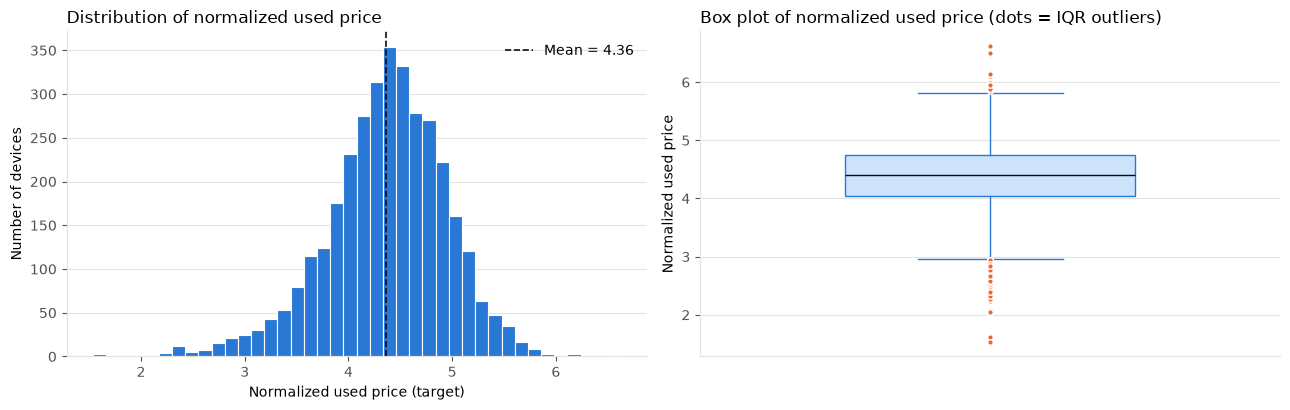

,normalized_used_price
count,"3,454.0000"
mean,4.3647
std,0.5889
min,1.5369
1%,2.6906
5%,3.3354
25%,4.0339
50%,4.4051
75%,4.7557
95%,5.2366


In [10]:
# Chart styling (consistent across the notebook)
BLUE, ORANGE = "#2a78d6", "#eb6834"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]   # fixed categorical order
TEXT, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"

def style_axis(ax, grid_axis="y"):
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    ax.spines["left"].set_color(GRID)
    ax.spines["bottom"].set_color(GRID)
    ax.tick_params(colors=MUTED)
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
ax1.hist(devices[TARGET], bins=40, color=BLUE, edgecolor="white", linewidth=0.8)
ax1.axvline(devices[TARGET].mean(), color=TEXT, linestyle="--", linewidth=1.2, label=f"Mean = {devices[TARGET].mean():.2f}")
ax1.set_title("Distribution of normalized used price", loc="left")
ax1.set_xlabel("Normalized used price (target)"); ax1.set_ylabel("Number of devices")
ax1.legend(frameon=False); style_axis(ax1)

ax2.boxplot(devices[TARGET], widths=0.5, patch_artist=True,
            boxprops=dict(facecolor="#cde2fb", color=BLUE), medianprops=dict(color=TEXT),
            whiskerprops=dict(color=BLUE), capprops=dict(color=BLUE),
            flierprops=dict(marker="o", markersize=4, markerfacecolor=ORANGE, markeredgecolor="white"))
ax2.set_title("Box plot of normalized used price (dots = IQR outliers)", loc="left")
ax2.set_ylabel("Normalized used price"); ax2.set_xticks([]); style_axis(ax2)
plt.tight_layout(); plt.show()

devices[TARGET].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).to_frame()

### Which currency? Checking the normalization against real launch prices

If the normalized price is ln(price in €), then $e^{\text{normalized price}}$ should reproduce known European launch prices. We check the most expensive new devices in the file:

In [11]:
check_cols = ["device_brand", "screen_size", "internal_memory", "5g", "release_year", "normalized_new_price"]
known = devices.loc[[646, 647, 3207], check_cols].copy()
known["e^normalized_new_price (EUR)"] = np.exp(known["normalized_new_price"]).round(0)
known["Likely model (EU launch price)"] = ["iPhone XS Max 64 GB (EUR 1,249)", "iPhone XS 64 GB (EUR 1,149)",
                                          "Huawei Mate Xs 512 GB, 8-inch foldable (EUR 2,499)"]
print(f"Median new price : EUR {np.exp(devices['normalized_new_price'].median()):,.0f}")
print(f"Median used price: EUR {np.exp(devices[TARGET].median()):,.0f}")
known

Median new price : EUR 190
Median used price: EUR 82


,device_brand,screen_size,internal_memory,5g,release_year,normalized_new_price,e^normalized_new_price (EUR),Likely model (EU launch price)
646,Apple,15.3700,64.0000,no,2018,7.1312,"1,250.0000","iPhone XS Max 64 GB (EUR 1,249)"
647,Apple,12.9000,64.0000,no,2018,7.0478,"1,150.0000","iPhone XS 64 GB (EUR 1,149)"
3207,Huawei,20.3200,512.0000,yes,2020,7.8478,"2,560.0000","Huawei Mate Xs 512 GB, 8-inch foldable (EUR 2,..."


The exponentials match the real euro launch prices almost exactly (€1,250 vs €1,249, €1,150 vs €1,149, €2,560 vs €2,499). We therefore treat the normalized prices as **ln(price in €)**. This is our own inference: the Kaggle page does not state it.

The target is roughly **bell-shaped** (as expected for a log-transformed price), with a longer tail on the low side (very cheap basic phones). Because it is already on a compressed scale, we model it **directly** – no extra target transformation is applied, and every algorithm sees exactly the same target.

## Step 3.4: Numeric Feature Distributions

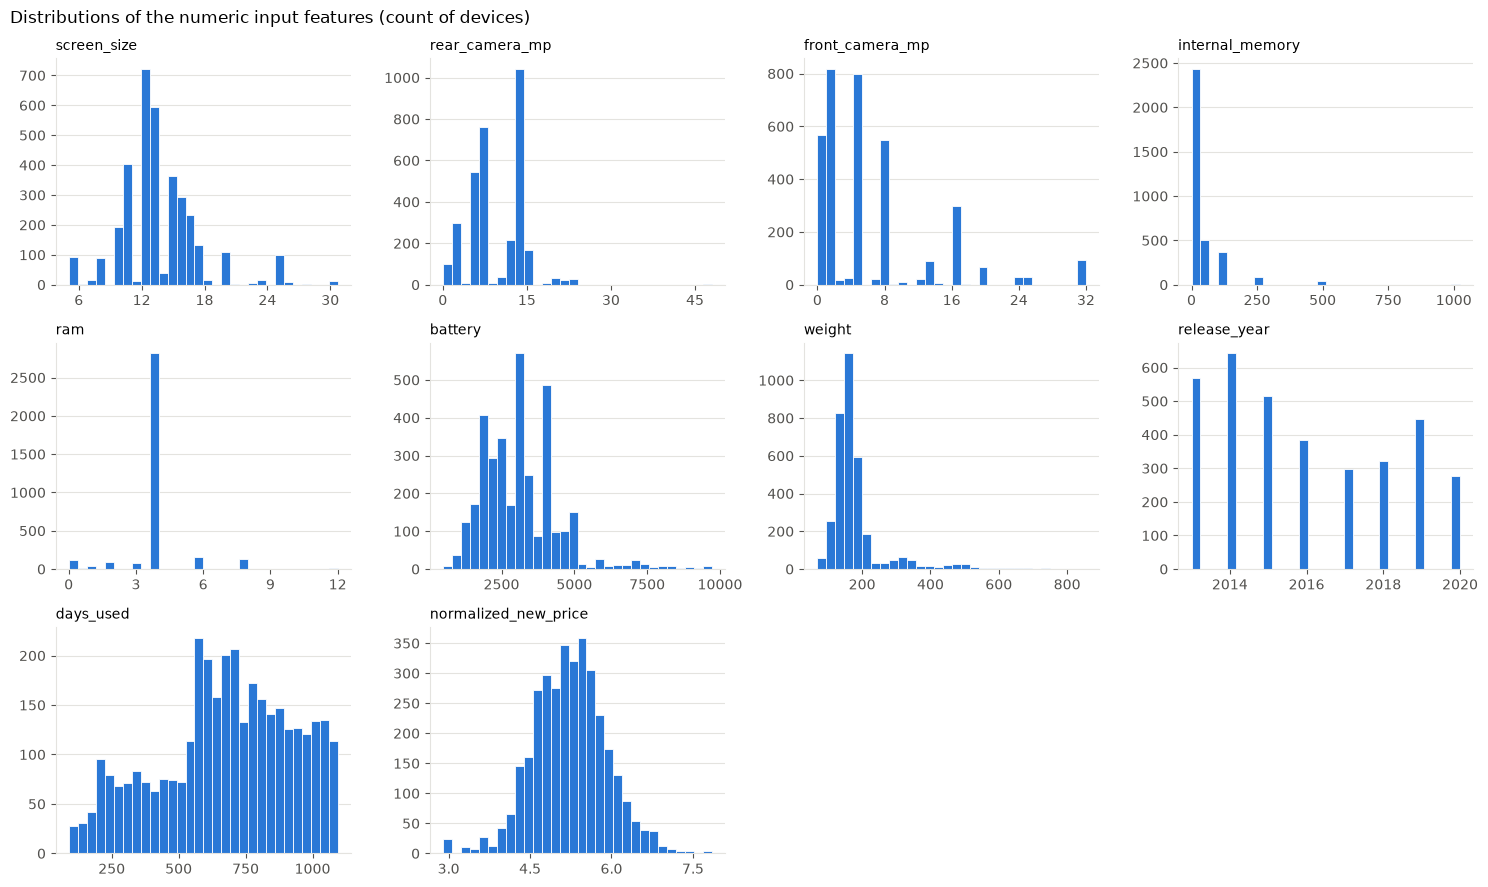

In [12]:
numeric_cols = devices.select_dtypes(include="number").columns.drop(TARGET).tolist()
fig, axes = plt.subplots(3, 4, figsize=(15, 9))
for ax, col in zip(axes.ravel(), numeric_cols):
    ax.hist(devices[col].dropna(), bins=30, color=BLUE, edgecolor="white", linewidth=0.6)
    ax.set_title(col, loc="left", fontsize=10); style_axis(ax)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
for ax in axes.ravel()[len(numeric_cols):]:
    ax.set_visible(False)
fig.suptitle("Distributions of the numeric input features (count of devices)", x=0.01, ha="left")
plt.tight_layout(); plt.show()

`internal_memory`, `battery` and `weight` are **right-skewed** (a few tablets with very large batteries/weights, a few devices with 512–1024 GB). `ram` is dominated by 4 GB. These are real device specifications, not errors – scaling (Step 6) and tree-based models handle them well.

## Step 3.5: Categorical Feature Distributions

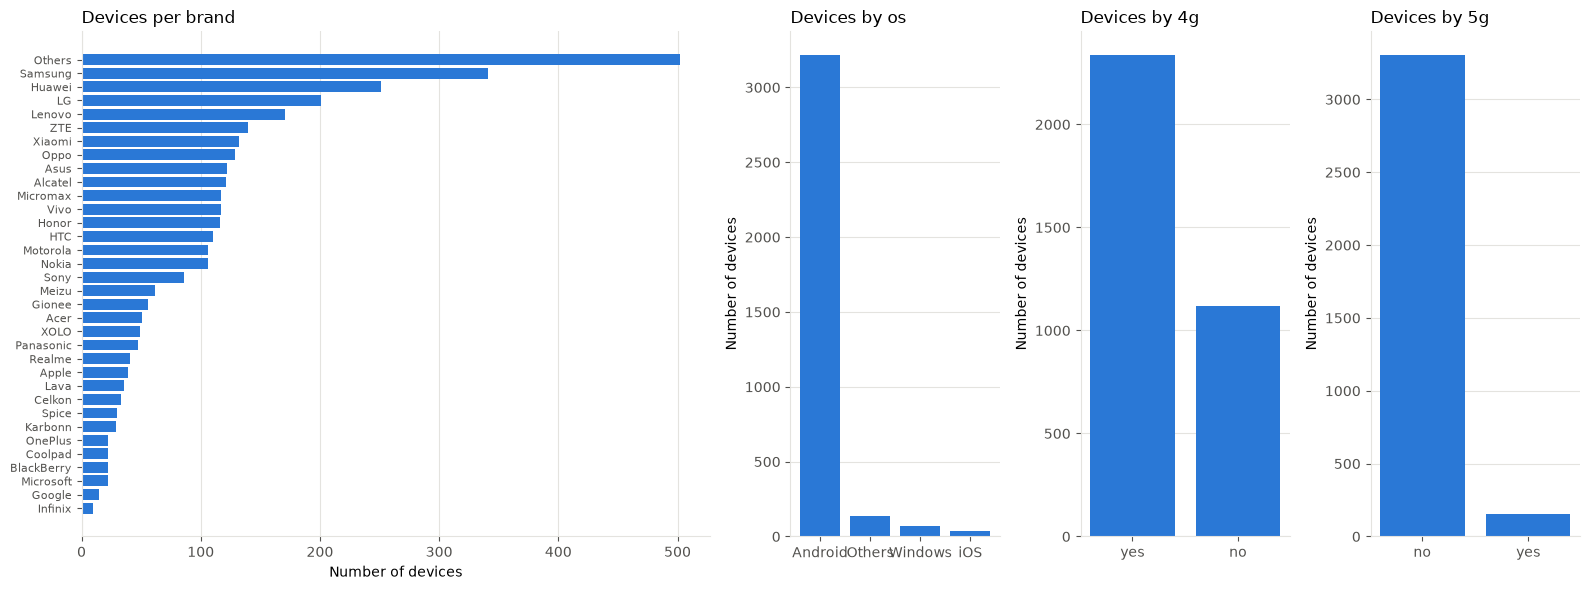

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(16, 6), gridspec_kw={"width_ratios": [3, 1, 1, 1]})
brand_counts = devices["device_brand"].value_counts()
axes[0].barh(brand_counts.index, brand_counts.values, color=BLUE)
axes[0].invert_yaxis(); axes[0].set_title("Devices per brand", loc="left"); axes[0].set_xlabel("Number of devices")
axes[0].tick_params(axis="y", labelsize=8); style_axis(axes[0], "x")
for ax, col in zip(axes[1:], ["os", "4g", "5g"]):
    counts = devices[col].value_counts()
    ax.bar(counts.index, counts.values, color=BLUE)
    ax.set_title(f"Devices by {col}", loc="left"); ax.set_ylabel("Number of devices"); style_axis(ax)
plt.tight_layout(); plt.show()

## Step 3.6: Relationships with the Used Price

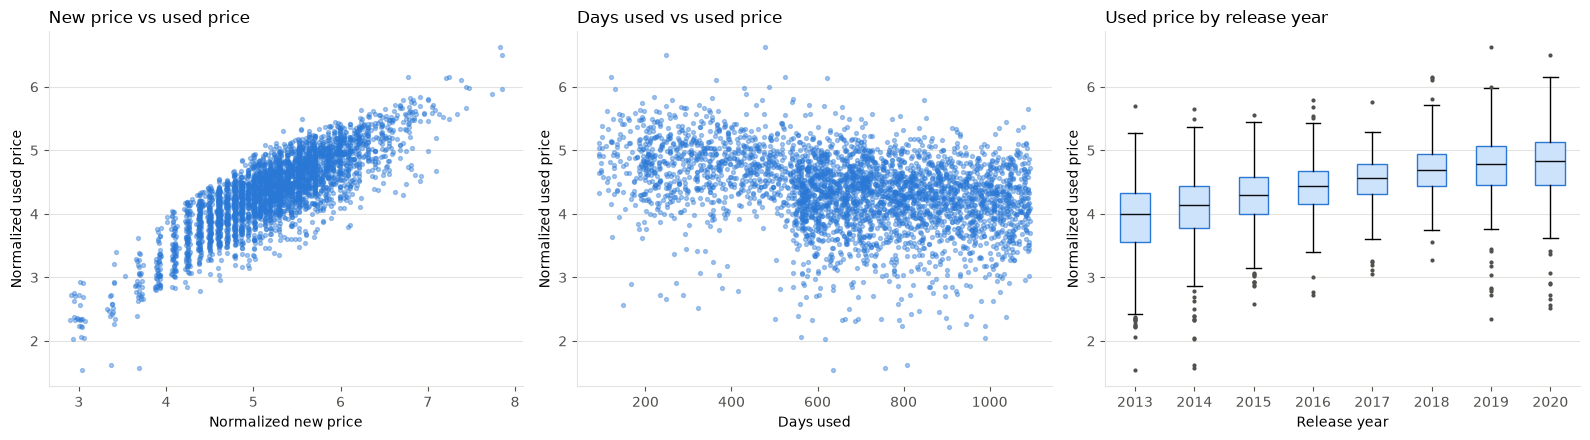

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].scatter(devices["normalized_new_price"], devices[TARGET], s=8, alpha=0.4, color=BLUE)
axes[0].set_title("New price vs used price", loc="left")
axes[0].set_xlabel("Normalized new price"); axes[0].set_ylabel("Normalized used price")

axes[1].scatter(devices["days_used"], devices[TARGET], s=8, alpha=0.4, color=BLUE)
axes[1].set_title("Days used vs used price", loc="left")
axes[1].set_xlabel("Days used"); axes[1].set_ylabel("Normalized used price")

years = sorted(devices["release_year"].unique())
axes[2].boxplot([devices.loc[devices["release_year"] == yr, TARGET] for yr in years],
                patch_artist=True, boxprops=dict(facecolor="#cde2fb", color=BLUE), medianprops=dict(color=TEXT),
                flierprops=dict(marker="o", markersize=3, markerfacecolor=MUTED, markeredgecolor="none"))
axes[2].set_xticks(range(1, len(years) + 1), years)
axes[2].set_title("Used price by release year", loc="left")
axes[2].set_xlabel("Release year"); axes[2].set_ylabel("Normalized used price")
for ax in axes: style_axis(ax)
plt.tight_layout(); plt.show()

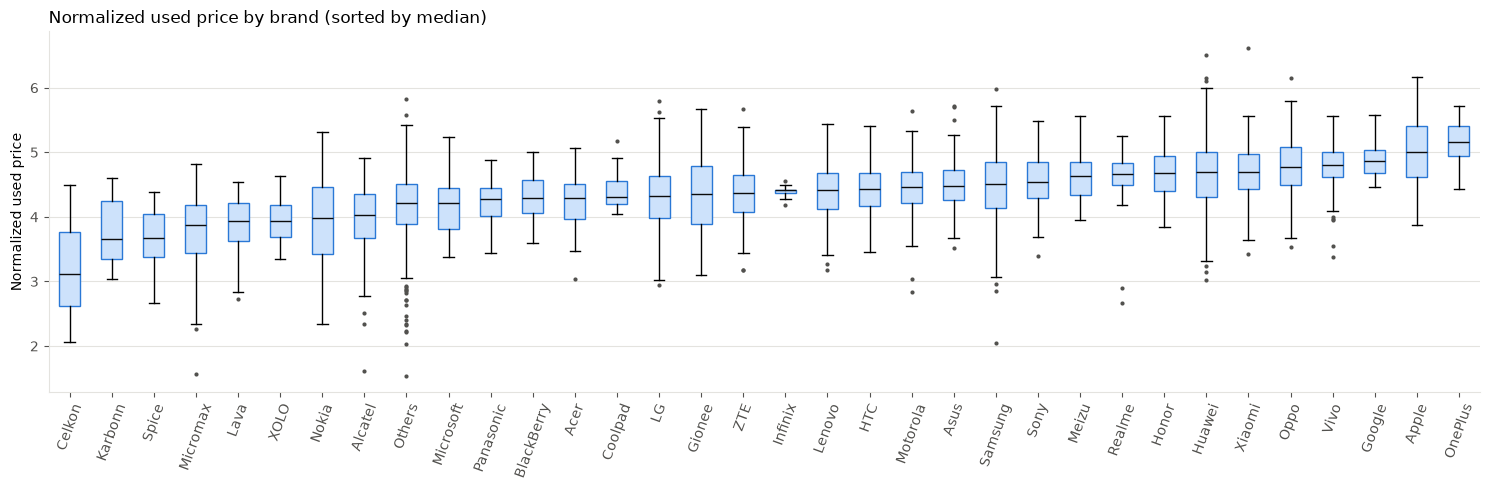

,count,median,mean
device_brand,,,
OnePlus,22,5.1660,5.1522
Apple,39,5.0119,5.0046
Google,15,4.8701,4.8857
Vivo,117,4.8088,4.7781
Oppo,129,4.7757,4.7553
Xiaomi,132,4.6926,4.7106
Huawei,251,4.6902,4.6546
Honor,116,4.6833,4.6653
Realme,41,4.6641,4.5943


In [15]:
# Brand-level comparison: median used price per brand (brands sorted by median)
order = devices.groupby("device_brand")[TARGET].median().sort_values().index
fig, ax = plt.subplots(figsize=(15, 5))
ax.boxplot([devices.loc[devices["device_brand"] == b, TARGET] for b in order],
           patch_artist=True, boxprops=dict(facecolor="#cde2fb", color=BLUE), medianprops=dict(color=TEXT),
           flierprops=dict(marker="o", markersize=3, markerfacecolor=MUTED, markeredgecolor="none"))
ax.set_xticks(range(1, len(order) + 1), order)
ax.set_title("Normalized used price by brand (sorted by median)", loc="left")
ax.set_ylabel("Normalized used price"); ax.tick_params(axis="x", rotation=70)
style_axis(ax); plt.tight_layout(); plt.show()

devices.groupby("device_brand")[TARGET].agg(["count", "median", "mean"]).sort_values("median", ascending=False).head(10)

In [16]:
# Price by network support and OS
for col in ["os", "4g", "5g"]:
    print(devices.groupby(col)[TARGET].agg(["count", "mean", "median"]).round(3), "\n")

         count   mean  median
os                           
Android   3214 4.4080  4.4240
Others     137 3.3070  3.2840
Windows     67 4.1550  4.0340
iOS         36 4.9570  4.9300 

     count   mean  median
4g                       
no    1119 3.8960  3.9500
yes   2335 4.5890  4.5730 

     count   mean  median
5g                       
no    3302 4.3250  4.3720
yes    152 5.2250  5.1780 



## Step 3.7: Correlation Analysis (numeric features)

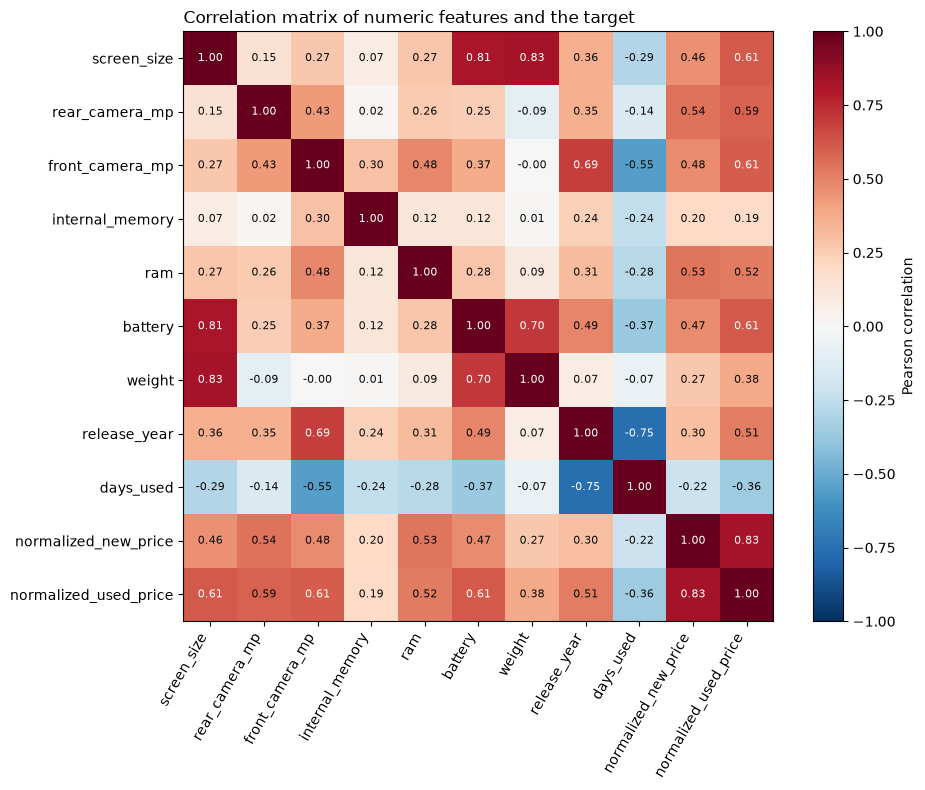

,Correlation with used price
normalized_new_price,0.8345
screen_size,0.6148
battery,0.6136
front_camera_mp,0.6081
rear_camera_mp,0.5873
ram,0.5203
release_year,0.5098
weight,0.3824
internal_memory,0.1910
days_used,-0.3583


In [17]:
corr = devices[numeric_cols + [TARGET]].corr()
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=60, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else TEXT)
fig.colorbar(im, ax=ax, label="Pearson correlation")
ax.set_title("Correlation matrix of numeric features and the target", loc="left")
plt.tight_layout(); plt.show()

corr[TARGET].drop(TARGET).sort_values(ascending=False).to_frame("Correlation with used price")

**Observations.** The used price is most strongly related to the **new price of the same model**, and also rises with screen size, cameras, battery, RAM and release year, while it falls as **days used** increases. Several specifications are correlated with each other (e.g. screen size, battery and weight – bigger devices have bigger batteries), which is no problem for the tree ensembles and is handled by regularisation in SVR and the MLP.

## Step 3.8: Outlier Investigation

We flag values outside 1.5 × IQR, then look at what they are **before** deciding anything.

In [18]:
def iqr_outliers(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)

outlier_summary = pd.DataFrame({
    col: {"IQR outliers": int(iqr_outliers(devices[col].dropna()).sum()),
          "min": devices[col].min(), "max": devices[col].max()}
    for col in numeric_cols + [TARGET]
}).T
outlier_summary

,IQR outliers,min,max
screen_size,450.0000,5.0800,30.7100
rear_camera_mp,5.0000,0.0800,48.0000
front_camera_mp,221.0000,0.0000,32.0000
internal_memory,138.0000,0.0100,"1,024.0000"
ram,635.0000,0.0200,12.0000
battery,77.0000,500.0000,"9,720.0000"
weight,368.0000,69.0000,855.0000
release_year,0.0000,"2,013.0000","2,020.0000"
days_used,0.0000,91.0000,"1,094.0000"
normalized_new_price,66.0000,2.9014,7.8478


In [19]:
print("Cheapest 5 devices (lowest used price):")
display(devices.nsmallest(5, TARGET)[["device_brand", "os", "4g", "internal_memory", "ram", "release_year", "normalized_new_price", TARGET]])
print("Most expensive 5 devices (highest used price):")
display(devices.nlargest(5, TARGET)[["device_brand", "os", "5g", "internal_memory", "ram", "release_year", "normalized_new_price", TARGET]])
print("Devices with less than 0.5 GB of RAM (basic feature phones):", (devices["ram"] < 0.5).sum())

Cheapest 5 devices (lowest used price):


,device_brand,os,4g,internal_memory,ram,release_year,normalized_new_price,normalized_used_price
885,Others,Others,no,32.0000,0.2500,2013,3.0421,1.5369
323,Micromax,Android,no,0.5000,0.2500,2014,3.6861,1.5728
533,Alcatel,Others,no,16.0000,0.2500,2014,3.3718,1.6174
2320,Others,Others,no,64.0000,0.2500,2014,2.9370,2.0334
2533,Samsung,Others,no,16.0000,4.0000,2014,3.0573,2.0528


Most expensive 5 devices (highest used price):


,device_brand,os,5g,internal_memory,ram,release_year,normalized_new_price,normalized_used_price
198,Xiaomi,Android,yes,512.0000,12.0000,2019,7.8233,6.6194
3207,Huawei,Android,yes,512.0000,8.0000,2020,7.8478,6.5004
645,Apple,iOS,no,"1,024.0000",4.0000,2018,6.7789,6.1590
34,Huawei,Android,yes,256.0000,8.0000,2020,7.2442,6.1535
2135,Oppo,Android,no,512.0000,4.0000,2018,7.2097,6.1433


Devices with less than 0.5 GB of RAM (basic feature phones): 118


**Decision: keep all outliers.** The cheapest devices are basic feature phones with tiny memory (e.g. 0.06 GB) and no 4G, and the most expensive ones are recent high-end devices with large storage and a high new price – both are **genuine market segments**, consistent with their other features. Large weights/batteries belong to tablets, which the dataset explicitly includes. Removing them would make the model unable to price these devices and would make the evaluation look better than it really is.

# Step 4: Data Cleaning

| # | Check | Finding | Action |
|---|---|---|---|
| 1 | Duplicate rows | 0 | nothing to remove |
| 2 | Inconsistent category spelling / spaces | checked below | strip whitespace (no-op if already clean) |
| 3 | Missing numeric values | 6 columns, ≤ 5.2 % | **impute inside the CV pipeline** (median of the training folds only) |
| 4 | Impossible values (negative / zero price, negative sizes) | checked below | drop only if found |
| 5 | Outliers | genuine feature phones & tablets | keep |
| 6 | Mixed currencies / markets | single normalized price scale, single collection | no conversion needed |

In [20]:
row_log = [("Original Kaggle file", len(devices))]

# 1. duplicates
devices = devices.drop_duplicates().reset_index(drop=True)
row_log.append(("After removing duplicate rows", len(devices)))

# 2. tidy text categories
categorical_raw = ["device_brand", "os", "4g", "5g"]
for col in categorical_raw:
    devices[col] = devices[col].astype(str).str.strip()
print("Category values after tidying:")
for col in ["os", "4g", "5g"]:
    print(f"  {col:<4}: {sorted(devices[col].unique())}")

# 3. physically impossible values (non-positive prices or sizes)
must_be_positive = ["screen_size", "internal_memory", "ram", "battery", "weight", "days_used",
                    "normalized_new_price", TARGET]
invalid = (devices[must_be_positive] <= 0).any(axis=1)
devices = devices[~invalid].reset_index(drop=True)
row_log.append(("After removing physically impossible values", len(devices)))

cleaning_log = pd.DataFrame(row_log, columns=["Step", "Rows"])
cleaning_log["Rows removed"] = cleaning_log["Rows"].shift(1, fill_value=cleaning_log["Rows"][0]) - cleaning_log["Rows"]
cleaning_log

Category values after tidying:
  os  : ['Android', 'Others', 'Windows', 'iOS']
  4g  : ['no', 'yes']
  5g  : ['no', 'yes']


,Step,Rows,Rows removed
0,Original Kaggle file,3454,0
1,After removing duplicate rows,3454,0
2,After removing physically impossible values,3454,0


Note that `front_camera_mp = 0` (2 devices without a selfie camera) is a legitimate value and was not treated as invalid. The cleaned dataset therefore keeps **every** genuine record – the experiment below really is on the **full dataset**.

# Step 5: Feature Selection – Input (X) and Output (y)

The dataset offers 14 input attributes. Following the Car Price notebook (8 features), we use **8 features**, so that the deployed web app asks the user for only 8 values. They were chosen by three criteria:

1. **Predictive value** – the EDA correlations (Step 3.7) plus a preliminary permutation-importance check with a HistGradientBoosting model: `normalized_new_price` dominates, followed by `internal_memory`, `weight`, the two cameras, `screen_size` and `days_used`; `os`, `4g`, `5g` and `ram` add almost nothing once these are known (OS is nearly implied by the brand, 4G/5G by the release year).
2. **Ease of entry for a user** – a seller knows the brand, storage, camera MP, screen size, release year and how long they have used the phone. `release_year` was preferred over `weight` (similar predictive value) because users rarely know their phone's weight.
3. **No leakage** (below).

| Kept (8) | Dropped (6) |
|---|---|
| normalized_new_price, device_brand, internal_memory, rear_camera_mp, front_camera_mp, screen_size, release_year, days_used | os, 4g, 5g, ram, battery, weight |

> **Honesty note.** The feature choice used a preliminary check on this same dataset, so the cross-validation scores below may be very slightly optimistic. Step 10.5 measures what dropping the 6 features costs by re-running the winning algorithm with **all 14** features on the same folds.

Leakage check:

* **normalized_new_price** – the price of a **new** unit of the same model. It is **not** derived from the used price and is known (public list price) at the moment someone wants to value a used device, so it is a legitimate input – it is exactly what a human valuer would look up first.
* **days_used**, **release_year** – known at prediction time (age of the device).
* No column is a copy, rank, or transformation of the target, and the target itself is removed from X.

In [21]:
numeric_features = ["normalized_new_price", "internal_memory", "rear_camera_mp", "front_camera_mp",
                    "screen_size", "release_year", "days_used"]
categorical_features = ["device_brand"]
FEATURES = numeric_features + categorical_features
assert len(FEATURES) == 8

ALL_FEATURES = [c for c in devices.columns if c != TARGET]          # all 14, used only in Step 10.5

X = devices[FEATURES]
y = devices[TARGET]

assert TARGET not in X.columns
assert set(FEATURES) <= set(ALL_FEATURES)
print(f"Dropped attributes: {[c for c in ALL_FEATURES if c not in FEATURES]}")

print(f"Input features (X): {X.shape[1]} columns")
print(f"  numeric     ({len(numeric_features)}): {numeric_features}")
print(f"  categorical ({len(categorical_features)}): {categorical_features}")
print(f"Output (y)        : {TARGET}")
print(f"Number of devices : {len(X):,}")

Dropped attributes: ['os', '4g', '5g', 'ram', 'battery', 'weight']
Input features (X): 8 columns
  numeric     (7): ['normalized_new_price', 'internal_memory', 'rear_camera_mp', 'front_camera_mp', 'screen_size', 'release_year', 'days_used']
  categorical (1): ['device_brand']
Output (y)        : normalized_used_price
Number of devices : 3,454


# Step 6: Build the Pre-processing Pipeline

| Feature type | Step | Why |
|---|---|---|
| Numeric | **Median imputation** | fills the few missing specs; the median is robust to skewed columns |
| Numeric | **Standard scaling** | **essential for SVR and the MLP** (distance / gradient based); harmless for trees |
| Categorical | **Most-frequent imputation** | safety net for missing categories at prediction time |
| Categorical | **One-hot encoding** (`handle_unknown="ignore"`) | turns brands/OS into 0/1 columns without inventing an order; an unseen brand becomes "all zeros" instead of crashing |

### Preventing data leakage
The imputer, scaler and encoder live **inside** a `Pipeline`. In every cross-validation round the pipeline is **cloned and re-fitted on the 9 training folds only**, then applied to the test fold – so no statistic (median, mean, standard deviation, category list) is ever learned from test data.

In [22]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

print("Pre-processing pipeline created:")
preprocessor

Pre-processing pipeline created:


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

# Step 7: The 5 Regression Algorithms

The Car Price notebook used **Linear Regression, KNN, Decision Tree, Random Forest and Gradient Boosting** – none of these is used here. The five algorithms below are **genuinely different learning methods** (a kernel method, a randomized tree ensemble, an adaptive-boosting ensemble, a histogram-based boosting implementation and a neural network):

| # | Algorithm | How it predicts a price | Strengths | Weaknesses | Pre-processing needs |
|---|---|---|---|---|---|
| 1 | **Support Vector Regression (SVR, RBF kernel)** | Fits a smooth function in a kernel feature space; errors smaller than ε are ignored, so only "support vectors" shape the model | Strong on small/medium data, robust to small noise, smooth predictions | Training scales ~O(n²); very sensitive to feature scaling and C/ε/γ | **Scaling required**, numeric inputs only |
| 2 | **Extra Trees (Extremely Randomized Trees)** | Averages many trees; unlike Random Forest it uses the **whole** training set per tree and picks **random split thresholds** | Low variance, fast, captures interactions, little tuning | Large model file; cannot extrapolate beyond seen prices | None (scaling harmless) |
| 3 | **AdaBoost (AdaBoost.R2)** | Builds weak learners (shallow trees, depth 3) in sequence and **re-weights** the training samples that were predicted badly | Simple, focuses on hard cases | Sensitive to noisy targets/outliers; shallow learners can underfit | None |
| 4 | **Histogram-based Gradient Boosting** | Bins every feature into ≤ 255 histogram bins and fits trees to the **gradient of the loss** (LightGBM-style); has native missing-value support and L2 regularisation | Very fast, usually very accurate on tabular data | More hyper-parameters; can overfit small data without regularisation | None |
| 5 | **Multi-layer Perceptron (MLP) – neural network** | Two hidden layers (64 and 32 ReLU neurons) trained with Adam by back-propagation; early stopping uses 10 % of the **training** fold | Learns non-linear interactions | Needs scaling, sensitive to initialisation, less interpretable | **Scaling required** |

> **Note on AdaBoost vs HistGradientBoosting.** Both are *boosting* methods but they are different algorithms: AdaBoost re-weights **samples** using the AdaBoost.R2 rule, whereas HistGradientBoosting fits each new tree to the **loss gradient** on histogram-binned features. The instructor's `GradientBoostingRegressor` (exact-split gradient boosting) is not used.

### Settings – no tuning on the evaluation folds
To keep the comparison simple and fair (as in the reference notebook) we use **scikit-learn default hyper-parameters**, with only these practical, *pre-declared* choices:
* `random_state=42` for every randomized algorithm (reproducibility);
* MLP: `hidden_layer_sizes=(64, 32)`, `max_iter=2000`, `early_stopping=True` (the default of 200 iterations does not converge; early stopping takes its validation data from the **training** folds only).

No setting was chosen by looking at the test folds, so the cross-validation scores are honest estimates.

In [23]:
algorithms = {
    "SVR": SVR(kernel="rbf"),
    "Extra Trees": ExtraTreesRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    "AdaBoost": AdaBoostRegressor(random_state=RANDOM_STATE),
    "Hist Gradient Boosting": HistGradientBoostingRegressor(random_state=RANDOM_STATE),
    "MLP Neural Network": MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=2000, early_stopping=True,
                                       random_state=RANDOM_STATE),
}

# Safety check: none of the instructor's 5 algorithms is used
forbidden = {"LinearRegression", "KNeighborsRegressor", "DecisionTreeRegressor",
             "RandomForestRegressor", "GradientBoostingRegressor"}
used = {type(model).__name__ for model in algorithms.values()}
assert used.isdisjoint(forbidden) and len(used) == 5
print("Algorithms to compare:")
for number, (name, model) in enumerate(algorithms.items(), start=1):
    print(f"  {number}. {name:<24} ({type(model).__name__})")

Algorithms to compare:
  1. SVR                      (SVR)
  2. Extra Trees              (ExtraTreesRegressor)
  3. AdaBoost                 (AdaBoostRegressor)
  4. Hist Gradient Boosting   (HistGradientBoostingRegressor)
  5. MLP Neural Network       (MLPRegressor)


# Step 8: Set Up 10-Fold Cross Validation
## Step 8.1: Create the K-Fold Splitter

* `n_splits=10`, `shuffle=True` (the file is ordered by brand, so without shuffling a fold could contain a single brand), `random_state=42`.
* The folds are generated **once** and the **same 10 folds are used for all 5 algorithms**, so every algorithm is tested on exactly the same devices.

> **Why ordinary (not group) K-Fold?** A group-aware split would be needed if several rows described the same phone *model*, but the dataset has **no model-name column** and **no two rows share identical input features**, so the groups cannot be identified. Each row is treated as an independent device. The data were collected in one period (2021), so a time-ordered split is not applicable either.

In [24]:
K = 10
kfold = KFold(n_splits=K, shuffle=True, random_state=RANDOM_STATE)
folds = list(kfold.split(X))          # the SAME folds for every algorithm
print(f"{K}-Fold Cross Validation created (shuffle=True, random_state={RANDOM_STATE})")

10-Fold Cross Validation created (shuffle=True, random_state=42)


## Step 8.2: Inspect the Folds

In [25]:
fold_sizes = pd.DataFrame([{
    "Fold": f"Fold {i}",
    "Training devices": len(train_idx),
    "Testing devices": len(test_idx),
    "Mean target of test fold": y.iloc[test_idx].mean(),
    "Min target of test fold": y.iloc[test_idx].min(),
    "Max target of test fold": y.iloc[test_idx].max(),
} for i, (train_idx, test_idx) in enumerate(folds, start=1)]).set_index("Fold")

# every device is tested exactly once
all_test = np.concatenate([test_idx for _, test_idx in folds])
assert len(all_test) == len(X) and len(np.unique(all_test)) == len(X)
fold_sizes

,Training devices,Testing devices,Mean target of test fold,Min target of test fold,Max target of test fold
Fold,,,,,
Fold 1,3108,346,4.4005,2.3331,5.7420
Fold 2,3108,346,4.3573,2.3599,5.9960
Fold 3,3108,346,4.3572,1.6174,6.5004
Fold 4,3108,346,4.2829,1.5728,5.7891
Fold 5,3109,345,4.3328,2.3514,5.7920
Fold 6,3109,345,4.3906,1.5369,6.6194
Fold 7,3109,345,4.3619,2.3437,5.9593
Fold 8,3109,345,4.4118,2.5649,6.1590
Fold 9,3109,345,4.3909,2.0631,5.8207


# Step 9: Run 10-Fold Cross Validation for All 5 Algorithms

For each algorithm we build a pipeline (**pre-processing → algorithm**). For each of the 10 folds we:
1. `clone` the pipeline → a **fresh, untrained** copy,
2. **fit** it on the 9 training folds (pre-processing included),
3. **predict** the held-out fold,
4. record **RMSE, MAE, R²** and the **time** taken.

That is **5 algorithms × 10 folds = 50 model fits**. We also keep every out-of-fold prediction for later plots.

### Progress Bar (tqdm)
```
Hist Gradient Boosting, fold 7/10:  73%|███████▎  | 37/50 [00:41<00:09,  1.35fit/s]
```
| Part | Meaning |
|---|---|
| `Hist Gradient Boosting, fold 7/10` | algorithm and fold being trained now |
| `73%`, `37/50` | work completed |
| `00:41` | elapsed time |
| `00:09` | estimated remaining time (updates as faster/slower algorithms run) |

In [26]:
fold_records = []                                            # one row per (algorithm, fold)
oof_predictions = {name: np.zeros(len(y)) for name in algorithms}

total_steps = len(algorithms) * K
experiment_start = time.time()
with tqdm(total=total_steps, unit="fit") as progress_bar:
    for name, algorithm in algorithms.items():
        model = Pipeline([("preprocessor", preprocessor), ("regressor", algorithm)])
        for fold_number, (train_idx, test_idx) in enumerate(folds, start=1):
            progress_bar.set_description(f"{name}, fold {fold_number}/{K}")

            fold_model = clone(model)                                     # fresh copy
            t0 = time.time()
            fold_model.fit(X.iloc[train_idx], y.iloc[train_idx])          # train on 9 folds
            fit_seconds = time.time() - t0
            predictions = fold_model.predict(X.iloc[test_idx])            # test on 1 fold
            total_seconds = time.time() - t0

            y_true = y.iloc[test_idx]
            oof_predictions[name][test_idx] = predictions
            fold_records.append({
                "Algorithm": name, "Fold": fold_number,
                "Train size": len(train_idx), "Test size": len(test_idx),
                "RMSE": np.sqrt(mean_squared_error(y_true, predictions)),
                "MAE": mean_absolute_error(y_true, predictions),
                "R2": r2_score(y_true, predictions),
                "Fit time (s)": fit_seconds, "Total time (s)": total_seconds,
            })
            progress_bar.update(1)

        done = [r for r in fold_records if r["Algorithm"] == name]
        tqdm.write(f"{name:<24} -> mean RMSE = {np.mean([r['RMSE'] for r in done]):.4f}   "
                   f"({sum(r['Total time (s)'] for r in done):.1f} s)")
    progress_bar.set_description("Done")

fold_results = pd.DataFrame(fold_records)
assert len(fold_results) == len(algorithms) * K == 50
print(f"\n{K}-fold cross validation completed: {len(fold_results)} model-fold evaluations "
      f"in {time.time() - experiment_start:.1f} s.")


  0%|          | 0/50 [00:00<?, ?fit/s]


SVR, fold 1/10:   0%|          | 0/50 [00:00<?, ?fit/s]


SVR, fold 1/10:   2%|▏         | 1/50 [00:00<00:44,  1.10fit/s]


SVR, fold 2/10:   2%|▏         | 1/50 [00:00<00:44,  1.10fit/s]


SVR, fold 2/10:   4%|▍         | 2/50 [00:01<00:40,  1.18fit/s]


SVR, fold 3/10:   4%|▍         | 2/50 [00:01<00:40,  1.18fit/s]


SVR, fold 3/10:   6%|▌         | 3/50 [00:02<00:36,  1.27fit/s]


SVR, fold 4/10:   6%|▌         | 3/50 [00:02<00:36,  1.27fit/s]


SVR, fold 4/10:   8%|▊         | 4/50 [00:03<00:34,  1.33fit/s]


SVR, fold 5/10:   8%|▊         | 4/50 [00:03<00:34,  1.33fit/s]


SVR, fold 5/10:  10%|█         | 5/50 [00:03<00:34,  1.32fit/s]


SVR, fold 6/10:  10%|█         | 5/50 [00:03<00:34,  1.32fit/s]


SVR, fold 6/10:  12%|█▏        | 6/50 [00:04<00:33,  1.32fit/s]


SVR, fold 7/10:  12%|█▏        | 6/50 [00:04<00:33,  1.32fit/s]


SVR, fold 7/10:  14%|█▍        | 7/50 [00:05<00:31,  1.36fit/s]


SVR, fold 8/10:  14%|█▍        | 7/50 [00:05<00:31,  1.36fit/s]


SVR, fold 8/10:  16%|█▌        | 8/50 [00:05<00:29,  1.41fit/s]


SVR, fold 9/10:  16%|█▌        | 8/50 [00:05<00:29,  1.41fit/s]


SVR, fold 9/10:  18%|█▊        | 9/50 [00:06<00:29,  1.41fit/s]


SVR, fold 10/10:  18%|█▊        | 9/50 [00:06<00:29,  1.41fit/s]


SVR, fold 10/10:  20%|██        | 10/50 [00:07<00:27,  1.45fit/s]


SVR, fold 10/10:  20%|██        | 10/50 [00:07<00:27,  1.45fit/s]


Extra Trees, fold 1/10:  20%|██        | 10/50 [00:07<00:27,  1.45fit/s]

SVR                      -> mean RMSE = 0.2336   (7.3 s)



Extra Trees, fold 1/10:  22%|██▏       | 11/50 [00:07<00:22,  1.71fit/s]


Extra Trees, fold 2/10:  22%|██▏       | 11/50 [00:07<00:22,  1.71fit/s]


Extra Trees, fold 2/10:  24%|██▍       | 12/50 [00:08<00:19,  1.96fit/s]


Extra Trees, fold 3/10:  24%|██▍       | 12/50 [00:08<00:19,  1.96fit/s]


Extra Trees, fold 3/10:  26%|██▌       | 13/50 [00:08<00:17,  2.15fit/s]


Extra Trees, fold 4/10:  26%|██▌       | 13/50 [00:08<00:17,  2.15fit/s]


Extra Trees, fold 4/10:  28%|██▊       | 14/50 [00:08<00:15,  2.37fit/s]


Extra Trees, fold 5/10:  28%|██▊       | 14/50 [00:08<00:15,  2.37fit/s]


Extra Trees, fold 5/10:  30%|███       | 15/50 [00:09<00:14,  2.48fit/s]


Extra Trees, fold 6/10:  30%|███       | 15/50 [00:09<00:14,  2.48fit/s]


Extra Trees, fold 6/10:  32%|███▏      | 16/50 [00:09<00:12,  2.63fit/s]


Extra Trees, fold 7/10:  32%|███▏      | 16/50 [00:09<00:12,  2.63fit/s]


Extra Trees, fold 7/10:  34%|███▍      | 17/50 [00:09<00:12,  2.70fit/s]


Extra Trees, fold 8/10:  34%|███▍      | 17/50 [00:09<00:12,  2.70fit/s]


Extra Trees, fold 8/10:  36%|███▌      | 18/50 [00:10<00:11,  2.72fit/s]


Extra Trees, fold 9/10:  36%|███▌      | 18/50 [00:10<00:11,  2.72fit/s]


Extra Trees, fold 9/10:  38%|███▊      | 19/50 [00:10<00:11,  2.78fit/s]


Extra Trees, fold 10/10:  38%|███▊      | 19/50 [00:10<00:11,  2.78fit/s]


Extra Trees, fold 10/10:  40%|████      | 20/50 [00:10<00:10,  2.88fit/s]


Extra Trees, fold 10/10:  40%|████      | 20/50 [00:10<00:10,  2.88fit/s]


AdaBoost, fold 1/10:  40%|████      | 20/50 [00:10<00:10,  2.88fit/s]    

Extra Trees              -> mean RMSE = 0.2411   (3.3 s)



AdaBoost, fold 1/10:  42%|████▏     | 21/50 [00:11<00:10,  2.86fit/s]


AdaBoost, fold 2/10:  42%|████▏     | 21/50 [00:11<00:10,  2.86fit/s]


AdaBoost, fold 2/10:  44%|████▍     | 22/50 [00:11<00:09,  2.90fit/s]


AdaBoost, fold 3/10:  44%|████▍     | 22/50 [00:11<00:09,  2.90fit/s]


AdaBoost, fold 3/10:  46%|████▌     | 23/50 [00:11<00:10,  2.48fit/s]


AdaBoost, fold 4/10:  46%|████▌     | 23/50 [00:12<00:10,  2.48fit/s]


AdaBoost, fold 4/10:  48%|████▊     | 24/50 [00:12<00:10,  2.44fit/s]


AdaBoost, fold 5/10:  48%|████▊     | 24/50 [00:12<00:10,  2.44fit/s]


AdaBoost, fold 5/10:  50%|█████     | 25/50 [00:13<00:12,  2.08fit/s]


AdaBoost, fold 6/10:  50%|█████     | 25/50 [00:13<00:12,  2.08fit/s]


AdaBoost, fold 6/10:  52%|█████▏    | 26/50 [00:13<00:11,  2.08fit/s]


AdaBoost, fold 7/10:  52%|█████▏    | 26/50 [00:13<00:11,  2.08fit/s]


AdaBoost, fold 7/10:  54%|█████▍    | 27/50 [00:14<00:11,  2.04fit/s]


AdaBoost, fold 8/10:  54%|█████▍    | 27/50 [00:14<00:11,  2.04fit/s]


AdaBoost, fold 8/10:  56%|█████▌    | 28/50 [00:14<00:10,  2.11fit/s]


AdaBoost, fold 9/10:  56%|█████▌    | 28/50 [00:14<00:10,  2.11fit/s]


AdaBoost, fold 9/10:  58%|█████▊    | 29/50 [00:14<00:09,  2.16fit/s]


AdaBoost, fold 10/10:  58%|█████▊    | 29/50 [00:14<00:09,  2.16fit/s]


AdaBoost, fold 10/10:  60%|██████    | 30/50 [00:15<00:08,  2.30fit/s]


AdaBoost, fold 10/10:  60%|██████    | 30/50 [00:15<00:08,  2.30fit/s]


Hist Gradient Boosting, fold 1/10:  60%|██████    | 30/50 [00:15<00:08,  2.30fit/s]

AdaBoost                 -> mean RMSE = 0.2610   (4.5 s)



Hist Gradient Boosting, fold 1/10:  62%|██████▏   | 31/50 [00:15<00:08,  2.33fit/s]


Hist Gradient Boosting, fold 2/10:  62%|██████▏   | 31/50 [00:15<00:08,  2.33fit/s]


Hist Gradient Boosting, fold 2/10:  64%|██████▍   | 32/50 [00:16<00:08,  2.21fit/s]


Hist Gradient Boosting, fold 3/10:  64%|██████▍   | 32/50 [00:16<00:08,  2.21fit/s]


Hist Gradient Boosting, fold 3/10:  66%|██████▌   | 33/50 [00:16<00:07,  2.25fit/s]


Hist Gradient Boosting, fold 4/10:  66%|██████▌   | 33/50 [00:16<00:07,  2.25fit/s]


Hist Gradient Boosting, fold 4/10:  68%|██████▊   | 34/50 [00:17<00:06,  2.31fit/s]


Hist Gradient Boosting, fold 5/10:  68%|██████▊   | 34/50 [00:17<00:06,  2.31fit/s]


Hist Gradient Boosting, fold 5/10:  70%|███████   | 35/50 [00:17<00:06,  2.34fit/s]


Hist Gradient Boosting, fold 6/10:  70%|███████   | 35/50 [00:17<00:06,  2.34fit/s]


Hist Gradient Boosting, fold 6/10:  72%|███████▏  | 36/50 [00:17<00:05,  2.39fit/s]


Hist Gradient Boosting, fold 7/10:  72%|███████▏  | 36/50 [00:17<00:05,  2.39fit/s]


Hist Gradient Boosting, fold 7/10:  74%|███████▍  | 37/50 [00:18<00:05,  2.38fit/s]


Hist Gradient Boosting, fold 8/10:  74%|███████▍  | 37/50 [00:18<00:05,  2.38fit/s]


Hist Gradient Boosting, fold 8/10:  76%|███████▌  | 38/50 [00:18<00:04,  2.41fit/s]


Hist Gradient Boosting, fold 9/10:  76%|███████▌  | 38/50 [00:18<00:04,  2.41fit/s]


Hist Gradient Boosting, fold 9/10:  78%|███████▊  | 39/50 [00:19<00:04,  2.41fit/s]


Hist Gradient Boosting, fold 10/10:  78%|███████▊  | 39/50 [00:19<00:04,  2.41fit/s]


Hist Gradient Boosting, fold 10/10:  80%|████████  | 40/50 [00:19<00:04,  2.42fit/s]


Hist Gradient Boosting, fold 10/10:  80%|████████  | 40/50 [00:19<00:04,  2.42fit/s]


MLP Neural Network, fold 1/10:  80%|████████  | 40/50 [00:19<00:04,  2.42fit/s]     

Hist Gradient Boosting   -> mean RMSE = 0.2298   (4.2 s)



MLP Neural Network, fold 1/10:  82%|████████▏ | 41/50 [00:21<00:06,  1.31fit/s]


MLP Neural Network, fold 2/10:  82%|████████▏ | 41/50 [00:21<00:06,  1.31fit/s]


MLP Neural Network, fold 2/10:  84%|████████▍ | 42/50 [00:22<00:07,  1.00fit/s]


MLP Neural Network, fold 3/10:  84%|████████▍ | 42/50 [00:22<00:07,  1.00fit/s]


MLP Neural Network, fold 3/10:  86%|████████▌ | 43/50 [00:24<00:08,  1.19s/fit]


MLP Neural Network, fold 4/10:  86%|████████▌ | 43/50 [00:24<00:08,  1.19s/fit]


MLP Neural Network, fold 4/10:  88%|████████▊ | 44/50 [00:26<00:08,  1.39s/fit]


MLP Neural Network, fold 5/10:  88%|████████▊ | 44/50 [00:26<00:08,  1.39s/fit]


MLP Neural Network, fold 5/10:  90%|█████████ | 45/50 [00:27<00:07,  1.44s/fit]


MLP Neural Network, fold 6/10:  90%|█████████ | 45/50 [00:27<00:07,  1.44s/fit]


MLP Neural Network, fold 6/10:  92%|█████████▏| 46/50 [00:29<00:06,  1.56s/fit]


MLP Neural Network, fold 7/10:  92%|█████████▏| 46/50 [00:29<00:06,  1.56s/fit]


MLP Neural Network, fold 7/10:  94%|█████████▍| 47/50 [00:31<00:04,  1.64s/fit]


MLP Neural Network, fold 8/10:  94%|█████████▍| 47/50 [00:31<00:04,  1.64s/fit]


MLP Neural Network, fold 8/10:  96%|█████████▌| 48/50 [00:33<00:03,  1.66s/fit]


MLP Neural Network, fold 9/10:  96%|█████████▌| 48/50 [00:33<00:03,  1.66s/fit]


MLP Neural Network, fold 9/10:  98%|█████████▊| 49/50 [00:34<00:01,  1.64s/fit]


MLP Neural Network, fold 10/10:  98%|█████████▊| 49/50 [00:34<00:01,  1.64s/fit]


MLP Neural Network, fold 10/10: 100%|██████████| 50/50 [00:36<00:00,  1.58s/fit]


MLP Neural Network, fold 10/10: 100%|██████████| 50/50 [00:36<00:00,  1.58s/fit]


Done: 100%|██████████| 50/50 [00:36<00:00,  1.58s/fit]                          


Done: 100%|██████████| 50/50 [00:36<00:00,  1.39fit/s]

MLP Neural Network       -> mean RMSE = 0.2411   (16.5 s)

10-fold cross validation completed: 50 model-fold evaluations in 36.1 s.


# Step 10: Compare the Algorithms
## Step 10.1: RMSE of Each Algorithm on Each Fold

Each row is one round, each column one algorithm. The **lowest RMSE in each row** is highlighted.

In [27]:
per_fold_rmse = fold_results.pivot(index="Fold", columns="Algorithm", values="RMSE")[list(algorithms)]
per_fold_rmse.index = [f"Fold {i}" for i in per_fold_rmse.index]
per_fold_mae = fold_results.pivot(index="Fold", columns="Algorithm", values="MAE")[list(algorithms)]
per_fold_r2 = fold_results.pivot(index="Fold", columns="Algorithm", values="R2")[list(algorithms)]

wins = per_fold_rmse.idxmin(axis=1).value_counts().reindex(list(algorithms), fill_value=0)
print("Folds won (lowest RMSE) by each algorithm:", wins.to_dict())

(per_fold_rmse.style.format("{:.4f}")
    .highlight_min(axis=1, props="background-color: #c8ebd2; color: #0b0b0b; font-weight: bold;"))

Folds won (lowest RMSE) by each algorithm: {'SVR': 3, 'Extra Trees': 1, 'AdaBoost': 0, 'Hist Gradient Boosting': 6, 'MLP Neural Network': 0}


Algorithm,SVR,Extra Trees,AdaBoost,Hist Gradient Boosting,MLP Neural Network
Fold 1,0.2072,0.2357,0.2501,0.2220,0.2278
Fold 2,0.2278,0.2294,0.2549,0.2267,0.2415
Fold 3,0.2670,0.2598,0.2633,0.2478,0.2567
Fold 4,0.2336,0.2269,0.2605,0.2330,0.2369
Fold 5,0.2597,0.2603,0.2658,0.2474,0.2670
Fold 6,0.2171,0.2317,0.2438,0.2128,0.2209
Fold 7,0.2289,0.2533,0.2815,0.2316,0.2465
Fold 8,0.2294,0.2398,0.2640,0.2307,0.2347
Fold 9,0.2366,0.2405,0.2733,0.2275,0.2463
Fold 10,0.2289,0.2337,0.2525,0.2183,0.2328


In [28]:
# Full fold-level metrics table (all 50 evaluations)
fold_results.round(4)

,Algorithm,Fold,Train size,Test size,RMSE,MAE,R2,Fit time (s),Total time (s)
0,SVR,1,3108,346,0.2072,0.1631,0.8559,0.8234,0.9022
1,SVR,2,3108,346,0.2278,0.1793,0.8518,0.7144,0.7939
2,SVR,3,3108,346,0.2670,0.1992,0.8080,0.6304,0.7141
3,SVR,4,3108,346,0.2336,0.1778,0.8449,0.6000,0.6872
4,SVR,5,3109,345,0.2597,0.1874,0.7893,0.6899,0.7691
5,SVR,6,3109,345,0.2171,0.1690,0.8713,0.6544,0.7438
6,SVR,7,3109,345,0.2289,0.1754,0.8570,0.6020,0.6810
7,SVR,8,3109,345,0.2294,0.1863,0.8547,0.5609,0.6447
8,SVR,9,3109,345,0.2366,0.1865,0.8401,0.6340,0.7136
9,SVR,10,3109,345,0.2289,0.1690,0.8352,0.5565,0.6376


## Step 10.2: Summary Comparison Table

| Column | Meaning |
|---|---|
| **Mean RMSE** | average over 10 folds – **the ranking criterion (lower is better)** |
| **Std RMSE** | fold-to-fold variation – smaller = more consistent |
| **Best / Worst fold RMSE** | lowest and highest fold RMSE |
| **Mean MAE ± Std** | average absolute error (lower is better) |
| **Mean R² ± Std** | share of price variance explained (higher is better) |
| **Approx. typical error** | $e^{\text{MAE}}-1$, the typical % error in the euro price (since the target is ln €) |
| **CV time** | total train + predict time for all 10 folds |

In [29]:
grouped = fold_results.groupby("Algorithm")
summary = pd.DataFrame({
    "Mean RMSE": grouped["RMSE"].mean(),
    "Std RMSE": grouped["RMSE"].std(),
    "Best Fold RMSE": grouped["RMSE"].min(),
    "Worst Fold RMSE": grouped["RMSE"].max(),
    "Mean MAE": grouped["MAE"].mean(),
    "Std MAE": grouped["MAE"].std(),
    "Mean R2": grouped["R2"].mean(),
    "Std R2": grouped["R2"].std(),
    "Approx. typical error (%)": (np.exp(grouped["MAE"].mean()) - 1) * 100,
    "CV time (s)": grouped["Total time (s)"].sum(),
    "Folds won": wins,
}).sort_values("Mean RMSE")
summary.insert(0, "Rank", range(1, len(summary) + 1))
summary.index.name = "Algorithm"

# Save the results for submission
summary.round(5).to_csv("model_comparison_summary.csv")
fold_results.round(5).to_csv("fold_level_metrics.csv", index=False)
print("Saved: model_comparison_summary.csv, fold_level_metrics.csv")
print(f"Target scale for context: mean = {y.mean():.3f}, standard deviation = {y.std():.3f} (normalized units)\n")

(summary.style
    .format({c: "{:.4f}" for c in ["Mean RMSE", "Std RMSE", "Best Fold RMSE", "Worst Fold RMSE",
                                   "Mean MAE", "Std MAE", "Mean R2", "Std R2"]}
            | {"Approx. typical error (%)": "{:.1f}%", "CV time (s)": "{:.2f}"})
    .highlight_min(subset=["Mean RMSE", "Mean MAE"], props="background-color: #c8ebd2; color: #0b0b0b; font-weight: bold;")
    .highlight_max(subset=["Mean R2"], props="background-color: #c8ebd2; color: #0b0b0b; font-weight: bold;"))

Saved: model_comparison_summary.csv, fold_level_metrics.csv
Target scale for context: mean = 4.365, standard deviation = 0.589 (normalized units)



,Rank,Mean RMSE,Std RMSE,Best Fold RMSE,Worst Fold RMSE,Mean MAE,Std MAE,Mean R2,Std R2,Approx. typical error (%),CV time (s),Folds won
Algorithm,,,,,,,,,,,,
Hist Gradient Boosting,1,0.2298,0.0113,0.2128,0.2478,0.1814,0.0093,0.8462,0.0176,19.9%,4.15,6
SVR,2,0.2336,0.0179,0.2072,0.2670,0.1793,0.0108,0.8408,0.0247,19.6%,7.29,3
MLP Neural Network,3,0.2411,0.0137,0.2209,0.2670,0.1879,0.0107,0.8305,0.0228,20.7%,16.51,0
Extra Trees,4,0.2411,0.0124,0.2269,0.2603,0.1867,0.0099,0.8306,0.0206,20.5%,3.32,1
AdaBoost,5,0.2610,0.0112,0.2438,0.2815,0.2120,0.0105,0.8019,0.0178,23.6%,4.45,0


## Step 10.3: Visual Comparison

* **Chart 1** – mean RMSE (shorter = better), whiskers = ± 1 standard deviation over the 10 folds.
* **Chart 2** – RMSE of **every individual fold** (dots) and the mean (black bar): the spread shows consistency.
* **Chart 3** – RMSE fold by fold, one line per algorithm: shows whether rankings change between folds.
* **Charts 4 & 5** – mean MAE and mean R² with ± 1 std.

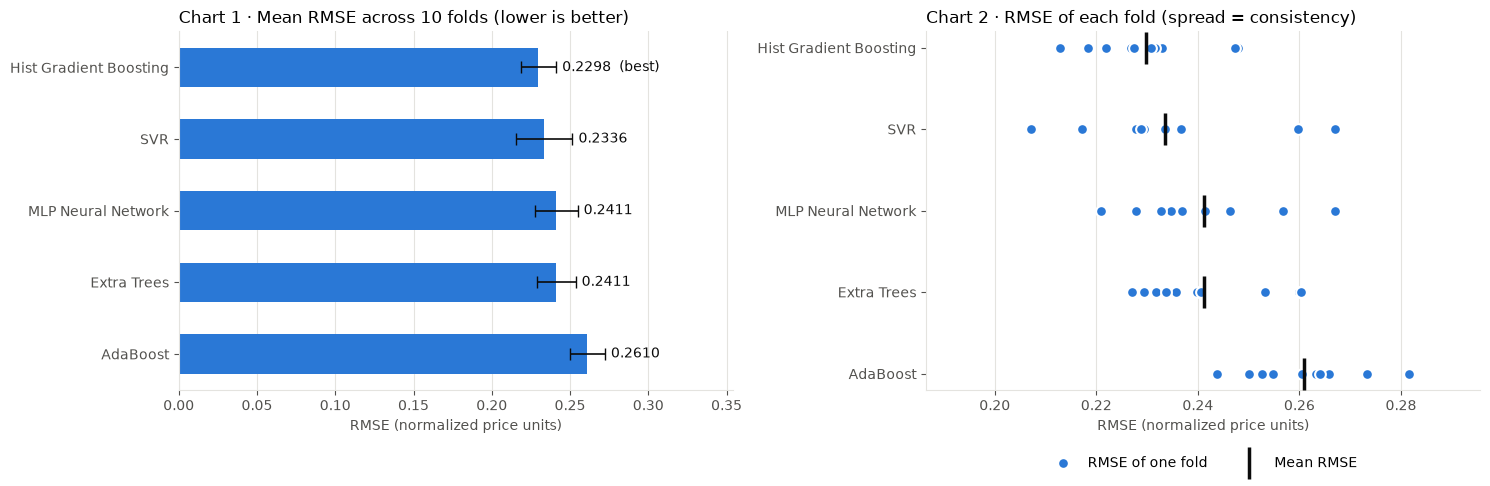

In [30]:
order = summary.index.tolist()                 # best algorithm first
positions = np.arange(len(order))
color_of = {name: SERIES[i] for i, name in enumerate(algorithms)}   # colour follows the algorithm

def bar_chart(ax, means, stds, title, xlabel, fmt="{:.4f}", best_label="(best)"):
    ax.barh(positions, means[order], height=0.55, color=BLUE,
            xerr=stds[order], error_kw=dict(ecolor=TEXT, elinewidth=1.2, capsize=4))
    best = means.idxmin()                         # lowest value of THIS metric
    for i, name in enumerate(order):
        ax.text(means[name] + stds[name] + means.max() * 0.015, i,
                fmt.format(means[name]) + (f"  {best_label}" if name == best else ""),
                va="center", color=TEXT, fontsize=10)
    ax.set_yticks(positions, order); ax.invert_yaxis()
    ax.set_xlim(0, (means + stds).max() * 1.3)
    ax.set_title(title, loc="left", fontsize=12); ax.set_xlabel(xlabel, color=MUTED)
    style_axis(ax, "x")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
bar_chart(ax1, summary["Mean RMSE"], summary["Std RMSE"],
          "Chart 1 · Mean RMSE across 10 folds (lower is better)", "RMSE (normalized price units)")

for i, name in enumerate(order):
    ax2.scatter(per_fold_rmse[name], np.full(K, i), s=60, color=BLUE, edgecolor="white", linewidth=1.5,
                zorder=3, label="RMSE of one fold" if i == 0 else None)
    ax2.scatter(summary.loc[name, "Mean RMSE"], i, marker="|", s=500, color=TEXT, linewidth=2.5, zorder=4,
                label="Mean RMSE" if i == 0 else None)
ax2.set_yticks(positions, order); ax2.invert_yaxis()
ax2.set_xlim(per_fold_rmse.values.min() * 0.9, per_fold_rmse.values.max() * 1.05)
ax2.set_title("Chart 2 · RMSE of each fold (spread = consistency)", loc="left", fontsize=12)
ax2.set_xlabel("RMSE (normalized price units)", color=MUTED); style_axis(ax2, "x")
ax2.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)
plt.tight_layout(); plt.show()

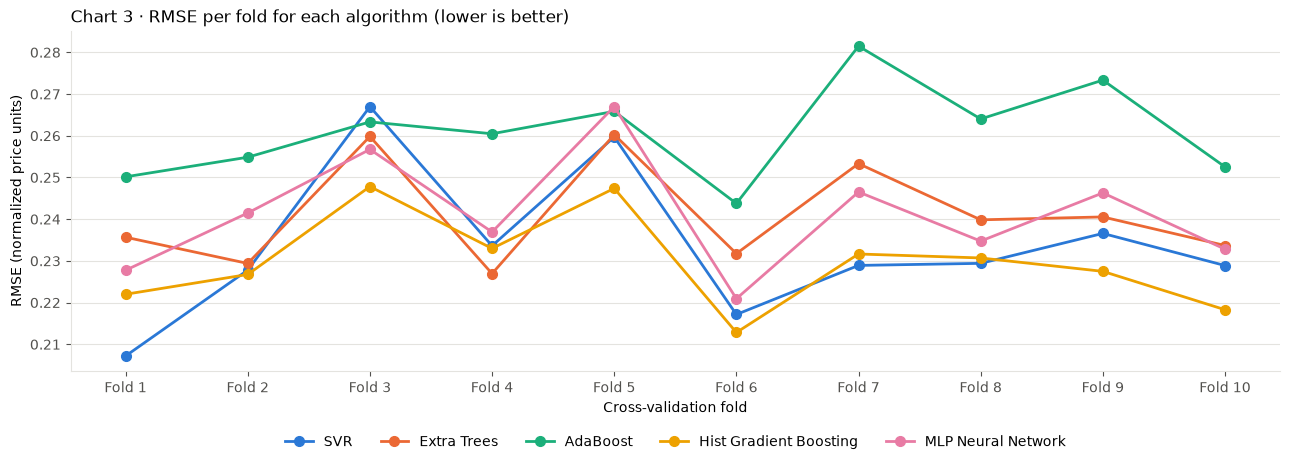

In [31]:
fig, ax = plt.subplots(figsize=(13, 4.8))
for name in algorithms:
    ax.plot(range(1, K + 1), per_fold_rmse[name].values, marker="o", markersize=7, linewidth=2,
            color=color_of[name], label=name)
ax.set_xticks(range(1, K + 1), [f"Fold {i}" for i in range(1, K + 1)])
ax.set_ylabel("RMSE (normalized price units)"); ax.set_xlabel("Cross-validation fold")
ax.set_title("Chart 3 · RMSE per fold for each algorithm (lower is better)", loc="left", fontsize=12)
ax.legend(frameon=False, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.15))
style_axis(ax); plt.tight_layout(); plt.show()

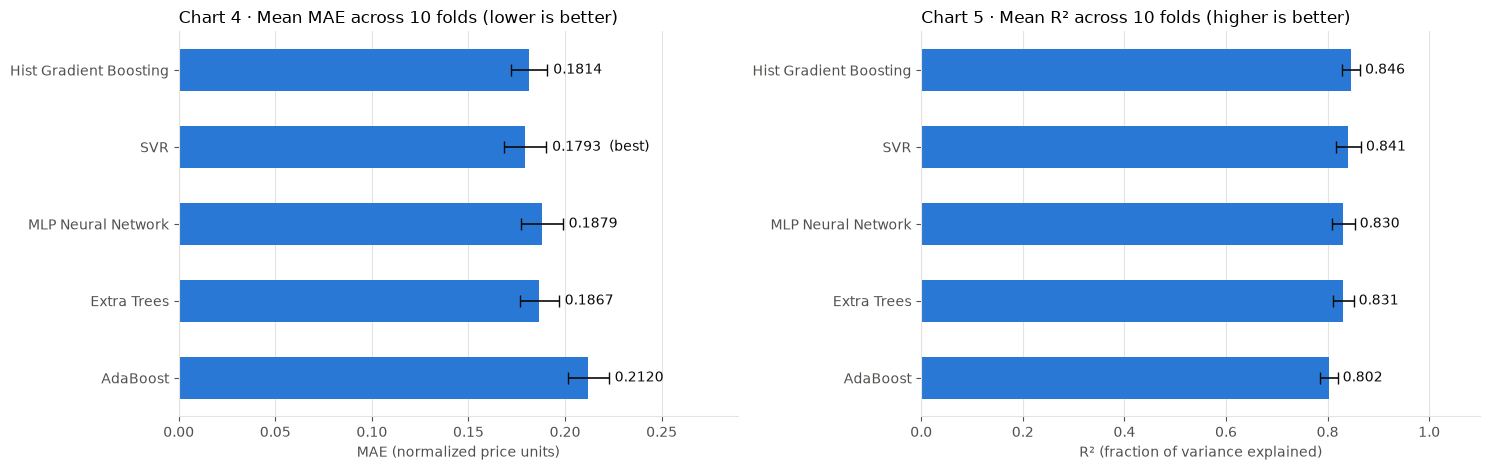

In [32]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.8))
bar_chart(ax1, summary["Mean MAE"], summary["Std MAE"],
          "Chart 4 · Mean MAE across 10 folds (lower is better)", "MAE (normalized price units)")

# R² - higher is better, so the best bar is the longest
r2_mean, r2_std = summary["Mean R2"], summary["Std R2"]
ax2.barh(positions, r2_mean[order], height=0.55, color=BLUE,
         xerr=r2_std[order], error_kw=dict(ecolor=TEXT, elinewidth=1.2, capsize=4))
for i, name in enumerate(order):
    ax2.text(r2_mean[name] + r2_std[name] + 0.01, i, f"{r2_mean[name]:.3f}", va="center", color=TEXT, fontsize=10)
ax2.set_yticks(positions, order); ax2.invert_yaxis(); ax2.set_xlim(0, 1.1)
ax2.set_title("Chart 5 · Mean R² across 10 folds (higher is better)", loc="left", fontsize=12)
ax2.set_xlabel("R² (fraction of variance explained)", color=MUTED); style_axis(ax2, "x")
plt.tight_layout(); plt.show()

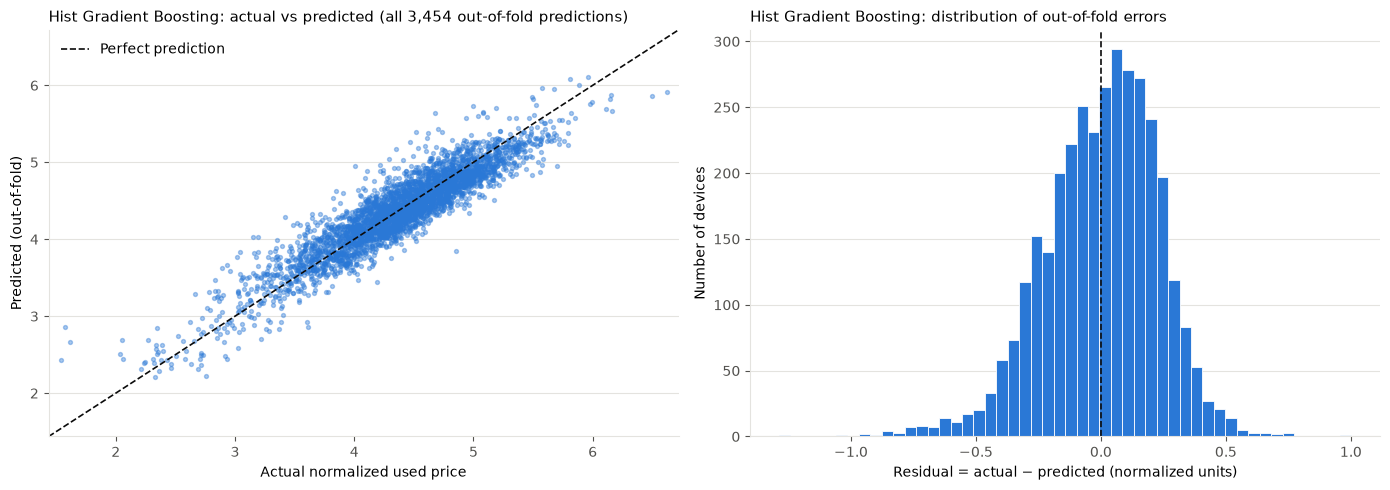

Out-of-fold RMSE over all devices: 0.2300
Share of devices with |error| < 0.20: 62.9%


In [33]:
# Out-of-fold predictions of the best algorithm: every device predicted by a model that never saw it
best_name = summary.index[0]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.scatter(y, oof_predictions[best_name], s=8, alpha=0.4, color=BLUE)
lims = [y.min() - 0.1, y.max() + 0.1]
ax1.plot(lims, lims, color=TEXT, linewidth=1.2, linestyle="--", label="Perfect prediction")
ax1.set_xlim(lims); ax1.set_ylim(lims)
ax1.set_xlabel("Actual normalized used price"); ax1.set_ylabel("Predicted (out-of-fold)")
ax1.set_title(f"{best_name}: actual vs predicted (all 3,454 out-of-fold predictions)", loc="left", fontsize=11)
ax1.legend(frameon=False); style_axis(ax1)

residuals = y - oof_predictions[best_name]
ax2.hist(residuals, bins=50, color=BLUE, edgecolor="white", linewidth=0.6)
ax2.axvline(0, color=TEXT, linestyle="--", linewidth=1.2)
ax2.set_xlabel("Residual = actual − predicted (normalized units)"); ax2.set_ylabel("Number of devices")
ax2.set_title(f"{best_name}: distribution of out-of-fold errors", loc="left", fontsize=11); style_axis(ax2)
plt.tight_layout(); plt.show()
print(f"Out-of-fold RMSE over all devices: {np.sqrt(mean_squared_error(y, oof_predictions[best_name])):.4f}")
print(f"Share of devices with |error| < 0.20: {(residuals.abs() < 0.20).mean() * 100:.1f}%")

## Step 10.4: Are the Differences Meaningful?

Because all algorithms were tested on the **same folds**, we can compare them **fold by fold** (a paired comparison). For each algorithm we compute how much worse it is than the winner on every fold. If an algorithm is worse on all 10 folds, the gap is systematic rather than luck.

> Fold scores share training data, so formal p-values from them are optimistic; we therefore report the paired differences descriptively.

In [34]:
best_name = summary.index[0]
paired = pd.DataFrame({
    "Mean RMSE gap vs best": [(per_fold_rmse[n] - per_fold_rmse[best_name]).mean() for n in order],
    "Std of gap": [(per_fold_rmse[n] - per_fold_rmse[best_name]).std() for n in order],
    "Folds where best is better": [int((per_fold_rmse[n] > per_fold_rmse[best_name]).sum()) for n in order],
    "Gap as % of best RMSE": [((per_fold_rmse[n] - per_fold_rmse[best_name]).mean()
                               / summary.loc[best_name, "Mean RMSE"] * 100) for n in order],
}, index=order)
paired.index.name = f"Compared with {best_name}"
paired.round(4)

,Mean RMSE gap vs best,Std of gap,Folds where best is better,Gap as % of best RMSE
Compared with Hist Gradient Boosting,,,,
Hist Gradient Boosting,0.0000,0.0000,0,0.0000
SVR,0.0038,0.0095,7,1.6688
MLP Neural Network,0.0113,0.0059,10,4.9309
Extra Trees,0.0113,0.0080,9,4.9331
AdaBoost,0.0312,0.0106,10,13.5737


## Step 10.5: What Did Using Only 8 Features Cost?

We re-run the **winning algorithm** with **all 14 attributes** on the **same 10 folds** (same pre-processing design) and compare.

In [35]:
best_name = summary.index[0]
all_numeric = [c for c in ALL_FEATURES if pd.api.types.is_numeric_dtype(devices[c])]
all_categorical = [c for c in ALL_FEATURES if c not in all_numeric]
preprocessor_all = ColumnTransformer([
    ("num", clone(numeric_pipeline), all_numeric),
    ("cat", clone(categorical_pipeline), all_categorical),
])
model_all = Pipeline([("preprocessor", preprocessor_all), ("regressor", clone(algorithms[best_name]))])
X_all = devices[ALL_FEATURES]

rmse_all = []
for train_idx, test_idx in tqdm(folds, desc=f"{best_name} with all 14 features", unit="fold"):
    m = clone(model_all).fit(X_all.iloc[train_idx], y.iloc[train_idx])
    rmse_all.append(np.sqrt(mean_squared_error(y.iloc[test_idx], m.predict(X_all.iloc[test_idx]))))
rmse_all = np.array(rmse_all)

feature_cost = pd.DataFrame({
    "Features": [f"8 selected (deployed)", "All 14"],
    "Mean RMSE": [per_fold_rmse[best_name].mean(), rmse_all.mean()],
    "Std RMSE": [per_fold_rmse[best_name].std(), rmse_all.std(ddof=1)],
}).set_index("Features")
increase = (per_fold_rmse[best_name].mean() / rmse_all.mean() - 1) * 100
print(f"Using 8 instead of 14 features changes {best_name}'s RMSE by {increase:+.1f}%.")
feature_cost.round(4)


Hist Gradient Boosting with all 14 features:   0%|          | 0/10 [00:00<?, ?fold/s]


Hist Gradient Boosting with all 14 features:  10%|█         | 1/10 [00:00<00:04,  1.80fold/s]


Hist Gradient Boosting with all 14 features:  20%|██        | 2/10 [00:01<00:04,  1.91fold/s]


Hist Gradient Boosting with all 14 features:  30%|███       | 3/10 [00:01<00:03,  1.98fold/s]


Hist Gradient Boosting with all 14 features:  40%|████      | 4/10 [00:02<00:02,  2.02fold/s]


Hist Gradient Boosting with all 14 features:  50%|█████     | 5/10 [00:02<00:02,  2.05fold/s]


Hist Gradient Boosting with all 14 features:  60%|██████    | 6/10 [00:02<00:01,  2.05fold/s]


Hist Gradient Boosting with all 14 features:  70%|███████   | 7/10 [00:03<00:01,  1.97fold/s]


Hist Gradient Boosting with all 14 features:  80%|████████  | 8/10 [00:04<00:01,  1.99fold/s]


Hist Gradient Boosting with all 14 features:  90%|█████████ | 9/10 [00:04<00:00,  2.00fold/s]


Hist Gradient Boosting with all 14 features: 100%|██████████| 10/10 [00:05<00:00,  2.01fold/s]


Hist Gradient Boosting with all 14 features: 100%|██████████| 10/10 [00:05<00:00,  2.00fold/s]

Using 8 instead of 14 features changes Hist Gradient Boosting's RMSE by +1.6%.


,Mean RMSE,Std RMSE
Features,,
8 selected (deployed),0.2298,0.0113
All 14,0.2262,0.0103


## Step 10.6: Interpretation of the Results

The cell below writes the key findings **directly from the measured results**, so the text always matches the numbers above.

In [36]:
best, second = summary.index[0], summary.index[1]
most_consistent = summary["Std RMSE"].idxmin()
fastest = summary["CV time (s)"].idxmin()
print(f"1. Lowest mean RMSE      : {best} ({summary.loc[best, 'Mean RMSE']:.4f} ± {summary.loc[best, 'Std RMSE']:.4f}), "
      f"won {summary.loc[best, 'Folds won']} of {K} folds.")
print(f"   Runner-up             : {second} ({summary.loc[second, 'Mean RMSE']:.4f}); gap = "
      f"{summary.loc[second, 'Mean RMSE'] - summary.loc[best, 'Mean RMSE']:.4f} "
      f"({paired.loc[second, 'Gap as % of best RMSE']:.1f}% of the best RMSE), best was better on "
      f"{paired.loc[second, 'Folds where best is better']}/{K} folds.")
print(f"2. Most consistent       : {most_consistent} (std RMSE = {summary.loc[most_consistent, 'Std RMSE']:.4f})")
print(f"3. Fastest               : {fastest} ({summary.loc[fastest, 'CV time (s)']:.2f} s); "
      f"best model took {summary.loc[best, 'CV time (s)']:.2f} s -> best is "
      f"{'also' if fastest == best else 'NOT'} the fastest.")
print(f"4. MAE ranking           : {list(summary.sort_values('Mean MAE').index)}")
print(f"   R² ranking            : {list(summary.sort_values('Mean R2', ascending=False).index)}")
print(f"   Worst model           : {summary.index[-1]} (RMSE {summary['Mean RMSE'].iloc[-1]:.4f}, "
      f"R² {summary['Mean R2'].iloc[-1]:.3f})")
print(f"5. Context               : target std = {y.std():.4f}; the best RMSE is "
      f"{summary.loc[best, 'Mean RMSE'] / y.std() * 100:.0f}% of it (R² = {summary.loc[best, 'Mean R2']:.3f}).")

1. Lowest mean RMSE      : Hist Gradient Boosting (0.2298 ± 0.0113), won 6 of 10 folds.
   Runner-up             : SVR (0.2336); gap = 0.0038 (1.7% of the best RMSE), best was better on 7/10 folds.
2. Most consistent       : AdaBoost (std RMSE = 0.0112)
3. Fastest               : Extra Trees (3.32 s); best model took 4.15 s -> best is NOT the fastest.
4. MAE ranking           : ['SVR', 'Hist Gradient Boosting', 'Extra Trees', 'MLP Neural Network', 'AdaBoost']
   R² ranking            : ['Hist Gradient Boosting', 'SVR', 'Extra Trees', 'MLP Neural Network', 'AdaBoost']
   Worst model           : AdaBoost (RMSE 0.2610, R² 0.802)
5. Context               : target std = 0.5889; the best RMSE is 39% of it (R² = 0.846).


### Observations (from our run – exact numbers are in the tables above)

> If your Colab library versions differ, the numbers may change in the 3rd–4th decimal place, but the overall pattern should be the same.

1. **Histogram-based Gradient Boosting has the lowest mean RMSE (0.2298 ± 0.0113)** and wins **6 of the 10 folds**. It also has the **highest mean R² (0.846)**.
2. **SVR is a close second (0.2336)** and has the **lowest mean MAE (0.1793 vs 0.1814)**. SVR's *typical* error is marginally smaller, while HistGradientBoosting makes fewer *large* errors, which RMSE punishes more. The RMSE gap is only ≈ 0.004 (1.7 %), smaller than either model's fold standard deviation, and SVR won 3 folds. **In practice these two are close.**
3. **MLP and Extra Trees tie for third (both ≈ 0.2411)**, about 5 % behind the winner. HistGradientBoosting beats them on 10/10 and 9/10 folds respectively, so that gap is systematic.
4. **AdaBoost is clearly the weakest (0.2610, R² 0.802)**. It is about 14 % worse than the winner and worse on every fold. Its default weak learners are depth-3 trees combined by sample re-weighting, which is not flexible enough and is sensitive to the noisy low-price devices.
5. **Consistency:** AdaBoost (std 0.0112) and HistGradientBoosting (std 0.0113) have practically the same, lowest fold-to-fold variation. AdaBoost is *consistently worse*, while HistGradientBoosting is *consistently good*. SVR varies the most (std 0.0178).
6. **Speed:** on 3,454 rows all algorithms are fast (≈ 3–16 s for all 10 folds). The best model is **not** the fastest (AdaBoost and Extra Trees are ≈ 1 s quicker), but the difference is irrelevant. The MLP is the slowest because of iterative back-propagation.
7. **Using 8 instead of 14 features** (Step 10.5) raises the winner's RMSE only from 0.2262 to 0.2298 (+1.6 %). The shorter, user-friendly form costs very little accuracy.
8. **How good is RMSE ≈ 0.23?** The target's standard deviation is 0.589, so the model explains about 85 % of the variance (R² = 0.846). Because the target is ln(€), a typical error (MAE ≈ 0.18) corresponds to roughly **±20 %** of the actual euro price. For example, a phone worth €150 is typically predicted within about €125–€180. About 63 % of devices are predicted within ±0.20 (≈ ±22 %).
9. **Deployment suitability:** HistGradientBoosting is selected by the pre-declared rule (lowest mean RMSE). It is also a good deployment model: the saved pipeline is small (≈ 0.15 MB), predicts in milliseconds, and handles missing values.

# Step 11: Train the Final Model
## Step 11.1: Select the Best Algorithm

**Cross validation is used to *choose* the algorithm and to *estimate* its accuracy on unseen devices – not to produce the final model.** The 50 fold models are discarded. The pre-declared selection rule is: **lowest mean 10-fold RMSE**.

In [37]:
best_algorithm_name = summary.index[0]
best_mean_rmse = summary.loc[best_algorithm_name, "Mean RMSE"]
best_std_rmse = summary.loc[best_algorithm_name, "Std RMSE"]
print(f"Best algorithm : {best_algorithm_name}")
print(f"Expected RMSE  : {best_mean_rmse:.4f} (± {best_std_rmse:.4f}) normalized price units")

Best algorithm : Hist Gradient Boosting
Expected RMSE  : 0.2298 (± 0.0113) normalized price units


## Step 11.2: Train the Best Algorithm on ALL the Cleaned Data

The complete pipeline (imputer + scaler + one-hot encoder + model) is fitted on all 3,454 devices. There is no separate test set: the cross-validation scores above are the estimate of how this model performs on new devices.

In [38]:
final_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("regressor", clone(algorithms[best_algorithm_name])),
])
final_model.fit(X, y)
print(f"Final {best_algorithm_name} pipeline trained on {len(X):,} devices.")

Final Hist Gradient Boosting pipeline trained on 3,454 devices.


## Step 11.3: Save the Trained Model and its Metadata

* `smartphone_price_model.joblib` – the **whole fitted pipeline**, so the web app applies *exactly* the same pre-processing as training.
* `model_metadata.json` – feature names/types/order, allowed categories, value ranges, target definition, CV results and library versions (used by the web app to build its form and validate inputs).

In [39]:
MODEL_FILE = "smartphone_price_model.joblib"
METADATA_FILE = "model_metadata.json"

joblib.dump(final_model, MODEL_FILE, compress=3)

metadata = {
    "model_name": "Smartphone Resale Price Predictor",
    "model_version": "1.0.0",
    "algorithm": best_algorithm_name,
    "estimator_class": type(final_model.named_steps["regressor"]).__name__,
    "trained_on_rows": int(len(X)),
    "target": {
        "name": TARGET,
        "description": "Normalized price of the used/refurbished device (as published in the dataset)",
        "unit": "ln(price in EUR), inferred from the data (the Kaggle page does not state it)",
    },
    "feature_order": FEATURES,
    "numeric_features": {c: {"min": float(X[c].min()), "max": float(X[c].max()),
                             "median": float(X[c].median())} for c in numeric_features},
    "categorical_features": {c: sorted(X[c].dropna().unique().tolist()) for c in categorical_features},
    "cv": {
        "folds": K, "shuffle": True, "random_state": RANDOM_STATE,
        "selection_rule": "lowest mean 10-fold RMSE",
        "summary": {name: {"mean_rmse": float(r["Mean RMSE"]), "std_rmse": float(r["Std RMSE"]),
                           "mean_mae": float(r["Mean MAE"]), "mean_r2": float(r["Mean R2"]),
                           "rank": int(r["Rank"])} for name, r in summary.iterrows()},
    },
    "dataset": {"title": "Used Phones & Tablets Pricing Dataset", "kaggle_ref": "ahsan81/used-handheld-device-data",
                "url": KAGGLE_PAGE, "license": "CC0: Public Domain", "file": DATA_FILE, "sha256": sha256},
    "library_versions": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
                         "scikit-learn": sklearn.__version__, "joblib": joblib.__version__},
}
with open(METADATA_FILE, "w") as f:
    json.dump(metadata, f, indent=2)

print(f"Saved '{MODEL_FILE}' ({os.path.getsize(MODEL_FILE) / 1e6:.2f} MB) and '{METADATA_FILE}'.")

Saved 'smartphone_price_model.joblib' (0.15 MB) and 'model_metadata.json'.


## Step 11.4: Reload the Saved Model (fresh object) and Verify It

In [40]:
loaded_model = joblib.load(MODEL_FILE)
with open(METADATA_FILE) as f:
    loaded_metadata = json.load(f)

# The reloaded pipeline must give exactly the same predictions as the in-memory one
check = X.sample(200, random_state=0)
assert np.allclose(loaded_model.predict(check), final_model.predict(check))
assert loaded_metadata["feature_order"] == FEATURES
print(f"Reloaded model: {type(loaded_model.named_steps['regressor']).__name__} - predictions identical to the trained model.")

Reloaded model: HistGradientBoostingRegressor - predictions identical to the trained model.


# Step 12: Execute the Application Phase
## Step 12.1: Take Input from the User

By default an example device is used so that **Run all** never stops. Set `USE_INTERACTIVE_INPUT = True` to type your own values.

In [41]:
USE_INTERACTIVE_INPUT = False

example_device = {
    "normalized_new_price": 5.6, "internal_memory": 64.0, "rear_camera_mp": 12.0, "front_camera_mp": 8.0,
    "screen_size": 15.34, "release_year": 2019, "days_used": 400, "device_brand": "Samsung",
}

def get_device_input():
    device = {}
    print("Enter the device specifications (ranges seen in the training data are shown):")
    for col in numeric_features:
        lo, hi = X[col].min(), X[col].max()
        device[col] = float(input(f"  {col} [{lo:g} - {hi:g}]: "))
    for col in categorical_features:
        print(f"  allowed {col}: {sorted(X[col].unique())}")
        device[col] = input(f"  {col}: ").strip()
    return device

user_input = get_device_input() if USE_INTERACTIVE_INPUT else example_device
for feature, value in user_input.items():
    print(f"  {feature:<22}: {value}")

  normalized_new_price  : 5.6
  internal_memory       : 64.0
  rear_camera_mp        : 12.0
  front_camera_mp       : 8.0
  screen_size           : 15.34
  release_year          : 2019
  days_used             : 400
  device_brand          : Samsung


## Step 12.2: Convert the Input into a Feature Vector

Same columns, same order as training. No manual encoding is needed – the saved pipeline does it.

In [42]:
feature_vector = pd.DataFrame([user_input])[FEATURES]
feature_vector

,normalized_new_price,internal_memory,rear_camera_mp,front_camera_mp,screen_size,release_year,days_used,device_brand
0,5.6000,64.0000,12.0000,8.0000,15.3400,2019,400,Samsung


## Step 12.3: Model Prediction

In [43]:
predicted = float(loaded_model.predict(feature_vector)[0])
assert np.isfinite(predicted)

print(f"Predicted normalized used price : {predicted:.3f}  (normalized price units)")
print(f"Typical error (10-fold CV RMSE) : ± {best_mean_rmse:.3f}")
price_eur = np.exp(predicted)
print(f"Estimated resale price          : EUR {price_eur:,.0f}  "
      f"(typical range EUR {np.exp(predicted - best_mean_rmse):,.0f} - EUR {np.exp(predicted + best_mean_rmse):,.0f})")
ratio = np.exp(predicted - user_input['normalized_new_price'])
print(f"Resale value                    : ≈ {ratio * 100:.0f}% of the new price")

Predicted normalized used price : 4.741  (normalized price units)
Typical error (10-fold CV RMSE) : ± 0.230
Estimated resale price          : EUR 114  (typical range EUR 91 - EUR 144)
Resale value                    : ≈ 42% of the new price


In [44]:
# Robustness checks used again by the web app
tests = {
    "Different brand (Apple, newer)":     {**example_device, "device_brand": "Apple",
                                           "normalized_new_price": 6.5, "release_year": 2020, "days_used": 200},
    "Missing camera values":              {**example_device, "rear_camera_mp": np.nan, "front_camera_mp": np.nan},
    "Brand never seen in training":       {**example_device, "device_brand": "UnknownBrandX"},
    "Minimum numeric values":             {**example_device, **{c: X[c].min() for c in numeric_features}},
    "Maximum numeric values":             {**example_device, **{c: X[c].max() for c in numeric_features}},
}
rows = []
for label, device in tests.items():
    value = float(loaded_model.predict(pd.DataFrame([device])[FEATURES])[0])
    rows.append({"Test case": label, "Prediction": value, "Finite": np.isfinite(value)})
pd.DataFrame(rows)

,Test case,Prediction,Finite
0,"Different brand (Apple, newer)",5.1108,True
1,Missing camera values,4.7015,True
2,Brand never seen in training,4.7486,True
3,Minimum numeric values,2.3499,True
4,Maximum numeric values,6.2278,True


# Step 13: Download the Artifacts

Set `DOWNLOAD_FILES = True` and run the cell to download the trained model, its metadata and the result tables from Colab (or use the **Files** panel on the left).

In [45]:
DOWNLOAD_FILES = False
artifacts = [MODEL_FILE, METADATA_FILE, "model_comparison_summary.csv", "fold_level_metrics.csv"]
for path in artifacts:
    print(f"  {path:<32} {os.path.getsize(path):>10,} bytes")
if IN_COLAB and DOWNLOAD_FILES:
    for path in artifacts:
        files.download(path)

  smartphone_price_model.joblib       151,808 bytes
  model_metadata.json                   3,825 bytes
  model_comparison_summary.csv            637 bytes
  fold_level_metrics.csv                3,312 bytes


# Step 14: Execute the Feedback Phase – Limitations & Future Improvements

**Limitations**
1. **Normalized target.** The dataset publishes prices only as ln(€), and we inferred that from the data (Step 3.3) because the Kaggle page does not document it. Prices are 2021 euros, not PKR, and are not adjusted for inflation.
2. **Dataset size.** 3,454 devices is a real but modest dataset; rare brands (e.g. Infinix – 10 devices, Google – 15) have few examples, so their predictions are less reliable.
3. **Missing information.** No model name, physical condition, battery health, seller type or region – all known to affect resale prices.
4. **Time coverage.** Devices released 2013–2020, data collected around 2021. Prices of newer devices and today's market may differ (concept drift).
5. **Possible near-duplicate models.** Without a model-name column we cannot group variants of the same model, so random K-fold may be slightly optimistic.
6. **Dependence on new price.** The strongest predictor is the new price of the same model; the app requires the user to supply it on the dataset's normalized scale.

**Future improvements**
1. **Hyper-parameter tuning** with *nested* cross-validation (e.g. `GridSearchCV` inside each training fold) – especially for SVR (C, ε, γ) and the MLP.
2. Collect **condition, battery health and model name** from marketplaces (OLX, Daraz, PriceOye) with prices in PKR.
3. Use **GroupKFold by model** once a model column is available.
4. Add prediction intervals (e.g. quantile regression with HistGradientBoosting) to show a price *range*.

# Conclusion

In this notebook we compared **5 regression algorithms that were not used in the Car Price notebook**: SVR, Extra Trees, AdaBoost, Histogram-based Gradient Boosting and an MLP neural network. They were evaluated on the **full Used Phones & Tablets Pricing dataset (3,454 devices, no rows removed)** with **8 input features**, using **10-fold cross validation** with identical folds, leakage-free pipelines and **RMSE** as the primary measure, plus MAE and R².

| Rank | Algorithm | Mean RMSE ± Std | Mean MAE | Mean R² |
|---|---|---|---|---|
| 1 | **Hist Gradient Boosting** | **0.2298 ± 0.0113** | 0.1814 | **0.846** |
| 2 | SVR | 0.2336 ± 0.0178 | **0.1793** | 0.841 |
| 3 | MLP Neural Network | 0.2411 ± 0.0137 | 0.1880 | 0.830 |
| 4 | Extra Trees | 0.2411 ± 0.0124 | 0.1867 | 0.831 |
| 5 | AdaBoost | 0.2610 ± 0.0112 | 0.2120 | 0.802 |

*(Errors are in normalized price units, from our run. See Step 10.2 for the values produced in your run.)*

- **Histogram-based Gradient Boosting** achieved the lowest mean RMSE. It was retrained on all 3,454 devices, saved as `smartphone_price_model.joblib`, reloaded, tested, and deployed in the **Smartphone Resale Price Predictor** web app (link at the top of this notebook).
- SVR was a close second (1.7 % behind, with the best MAE). MLP and Extra Trees were about 5 % behind, and **AdaBoost was clearly the weakest**.
- Using only 8 of the 14 attributes cost just **+1.6 % RMSE** and keeps the web form short.
- The strongest predictor of the used price is the **new price of the same model**. The used price also rises with storage, cameras, screen size and release year, and falls with days used.
- The main limitation is the data, not the algorithm: prices are only available as ln(€) from 2021 (the euro unit is inferred from the data, not documented), and condition, battery health and model name are not recorded.

**Lesson:** a fair comparison needs the same folds, preprocessing fitted only on training data, and several metrics. The best algorithm by RMSE (HistGradientBoosting) was not the best by MAE (SVR), and the differences among the top models were small compared with the fold-to-fold variation.